# Car Analysis — Practical Notebook

**Goal:** explain and test a car-search chatbot that uses data processing, text retrieval, regression, and image classification. Section 11 joins the explained cells into one Streamlit script instead of copying the processing functions.

| Topic | Notebook use | Results to read |
| --- | --- | --- |
| **Data processing and regression** | Section 4: `fit_transform` / `transform`; section 6: `fit` / `predict`, train/test split | MSE, RMSE, $R^2$, and comparison with a mean-price prediction |
| **Neural networks and images** | Sections 7–9: MobileNetV2, ReLU, softmax, cross-entropy, Adam | Confusion matrix, precision / recall / F1, and one example image |
| **Transformers and evaluation** | Sections 4–5: encoder-only, bi-encoder; sections 7 and 9: decision thresholds | The difference between retrieval scores and softmax probabilities |

**How to run:** choose a Python kernel and run the notebook from top to bottom. `RUN_STREAMLIT` is `True`, so Run All starts the app. Change it to `False` to skip startup. The final shutdown cell is fully commented out; stop the server manually when the demo ends. If MiniLM cannot download, search uses TF-IDF. If the CSV or CNN model is missing, the notebook downloads the version pinned to a GitHub commit.

**Scope:** this is a listing-retrieval chatbot, not a text-generation model. Its regression line describes listed prices and cannot value one car accurately.


## Install libraries

The next cell runs pip only for missing packages. TensorFlow is needed only for image recognition. If pip fails, the notebook prints a manual install command and continues with sections that do not need that package.


In [1]:
import importlib.util
import subprocess
import sys

CORE = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "PIL": "pillow",
    "streamlit": "streamlit",
    "sentence_transformers": "sentence-transformers",
    "kagglehub": "kagglehub",
    "certifi": "certifi",
}
OPTIONAL = {"tensorflow": "tensorflow"}


def install_packages(packages: list[str], label: str) -> bool:
    """Cài gói còn thiếu. Lỗi pip được in ra, không dừng các mục phía sau."""
    if not packages:
        return True
    print(f"Đang cài {label}:", ", ".join(packages))
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *packages])
        return True
    except (subprocess.CalledProcessError, OSError) as error:
        print(f"Không cài được {label}: {error}")
        print("Lệnh thủ công: python -m pip install " + " ".join(packages))
        return False


missing_core = [package for module, package in CORE.items() if importlib.util.find_spec(module) is None]
missing_optional = [package for module, package in OPTIONAL.items() if importlib.util.find_spec(module) is None]
if not missing_core and not missing_optional:
    print("Đã có đủ thư viện, bỏ qua pip.")
else:
    install_packages(missing_core, "thư viện bắt buộc")
    if not install_packages(missing_optional, "TensorFlow (chỉ cần cho CNN)"):
        print("Chưa có TensorFlow. Mục tìm xe và hồi quy vẫn chạy; mục nhận diện ảnh sẽ bỏ qua.")


Đã có đủ thư viện, bỏ qua pip.


## 1. Prepare the environment and paths

**Purpose.** Find the notebook, CSV, cache, and model folders so the same code works in both the notebook and the Streamlit script.

**Input / output.** The input is the working folder. The output is `DATASET_PATH`, `CNN_MODEL_PATH`, and functions that download missing files.

**Steps.**
1. In a notebook, use the path provided by Cursor/VS Code. If it is unavailable, find the `.ipynb` file with both `app-core` and `app-ui` tags. The notebook can therefore be renamed.
2. In a Streamlit script, get the folder from `__file__` and keep the real `st` object.
3. In the notebook, replace Streamlit caching with an in-memory cache so the functions still work.
4. `ensure_dataset()` and `ensure_cnn_artifacts()` download only missing local files. URLs are pinned to commit `0e09a00` in the project repository. Downloads keep HTTPS certificate and hostname checks, using system CAs plus `certifi`.



In [2]:
# Import và hằng số dùng chung; không cần script ứng dụng bên ngoài.
from __future__ import annotations

import argparse
import io
import hashlib
import json
import logging
import os
import sys
import time
import re
import shutil
import ssl
import unicodedata
import urllib.error
import urllib.request
import zipfile
from difflib import SequenceMatcher
from html import escape
from pathlib import Path
from typing import Any

import certifi
import streamlit as st
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Notebook thì tự tìm thư mục. Script Streamlit dùng __file__ của chính nó.
IN_NOTEBOOK = "ipykernel" in sys.modules or bool(globals().get("__IPYTHON__"))
DOWNLOAD_SSL_CONTEXT = ssl.create_default_context()
DOWNLOAD_SSL_CONTEXT.load_verify_locations(cafile=certifi.where())
assert DOWNLOAD_SSL_CONTEXT.check_hostname and DOWNLOAD_SSL_CONTEXT.verify_mode == ssl.CERT_REQUIRED


def _is_streamlit_source_notebook(path: Path) -> bool:
    """Nhận diện notebook nguồn bằng tag, không phụ thuộc tên file."""
    try:
        cells = json.loads(path.read_text(encoding="utf-8")).get("cells", [])
    except (OSError, UnicodeDecodeError, json.JSONDecodeError):
        return False
    tags = {
        tag
        for cell in cells
        for tag in cell.get("metadata", {}).get("tags", [])
    }
    return {"app-core", "app-ui"} <= tags


def locate_notebook_path() -> Path:
    """Tìm notebook nguồn dù file đã được đổi tên."""
    vscode_path = globals().get("__vsc_ipynb_file__")
    if vscode_path:
        path = Path(vscode_path).resolve()
        if path.is_file():
            return path

    roots = [Path.cwd().resolve(), *list(Path.cwd().resolve().parents)[:6]]
    directories = list(dict.fromkeys(
        (root / suffix).resolve()
        for root in roots
        for suffix in (Path(), Path("sources/Transformer"), Path("Project/sources/Transformer"))
    ))
    matches = [
        notebook
        for directory in directories
        for notebook in sorted(directory.glob("*.ipynb"))
        if _is_streamlit_source_notebook(notebook)
    ]
    matches = list(dict.fromkeys(matches))
    if len(matches) == 1:
        return matches[0]
    if matches:
        raise RuntimeError(
            "Có nhiều notebook chứa app-core/app-ui; hãy chạy trong Cursor/VS Code "
            "hoặc chỉ giữ một bản trong cây thư mục hiện tại."
        )

    created = Path.cwd().resolve() / "sources"
    (created / "Transformer").mkdir(parents=True, exist_ok=True)
    (created / "Dataset").mkdir(parents=True, exist_ok=True)
    (created / "CNN" / "outputs" / "car_cnn").mkdir(parents=True, exist_ok=True)
    raise FileNotFoundError(
        "Không tìm thấy notebook chứa các cell gắn tag app-core và app-ui "
        f"trong cây thư mục từ {Path.cwd().resolve()}."
    )


if IN_NOTEBOOK or "__file__" not in globals():
    NOTEBOOK_PATH = locate_notebook_path()
    assert _is_streamlit_source_notebook(NOTEBOOK_PATH)
    NOTEBOOK_DIR = NOTEBOOK_PATH.parent
    __file__ = str(NOTEBOOK_DIR / "_chatbot_notebook_runtime.py")
else:
    NOTEBOOK_PATH = None
    NOTEBOOK_DIR = Path(__file__).resolve().parent

HERE = Path(__file__).resolve().parent
SOURCES_DIR = HERE.parent
DATASET_PATH = SOURCES_DIR / "Dataset" / "car-price.csv"
CACHE_DIR = HERE / ".cache"

CNN_OUTPUT_DIR = SOURCES_DIR / "CNN" / "outputs" / "car_cnn"
CNN_MODEL_PATH = CNN_OUTPUT_DIR / "model.keras"
CNN_LABELS_PATH = CNN_OUTPUT_DIR / "labels.json"
CNN_META_PATH = CNN_OUTPUT_DIR / "meta.json"
CNN_METRICS_PATH = CNN_OUTPUT_DIR / "metrics.json"
CNN_LOW_CONFIDENCE = 0.60
PLOTS_DIR = CACHE_DIR / "plots"

# Artifact MobileNetV2 public, pin theo commit để lần tải sau tái lập được.
CNN_ARTIFACT_REPOSITORY = "ptnghia3502/PPR501-car-analysis"
CNN_ARTIFACT_REF = "0e09a00daa066b5082f1a250b8d22d9a01672d60"
CNN_ARTIFACT_BASE_URL = (
    f"https://raw.githubusercontent.com/{CNN_ARTIFACT_REPOSITORY}/"
    f"{CNN_ARTIFACT_REF}/sources/CNN/outputs/car_cnn"
)
CNN_HISTORY_PATH = CNN_OUTPUT_DIR / "history.json"
CNN_ARTIFACTS = {
    "model.keras": CNN_MODEL_PATH,
    "labels.json": CNN_LABELS_PATH,
    "meta.json": CNN_META_PATH,
    "metrics.json": CNN_METRICS_PATH,
    "history.json": CNN_HISTORY_PATH,
}
DATASET_KAGGLE_HANDLE = "qucvinhdng/automobile-dataset"
DATASET_URL = (
    f"https://raw.githubusercontent.com/{CNN_ARTIFACT_REPOSITORY}/"
    f"{CNN_ARTIFACT_REF}/sources/Dataset/car-price.csv"
)
SAMPLE_IMAGE_URL = (
    f"https://raw.githubusercontent.com/{CNN_ARTIFACT_REPOSITORY}/"
    f"{CNN_ARTIFACT_REF}/sources/Dataset/Test/Audi/1000.jpg"
)

DEFAULT_EMBEDDING_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_NAME = os.getenv("CAR_EMBEDDING_MODEL", "").strip() or DEFAULT_EMBEDDING_MODEL
EMBEDDING_DEVICE = os.getenv("CAR_EMBEDDING_DEVICE") or None
DEFAULT_TOP_K = 5
RETRIEVAL_MODES = ("Hybrid", "Semantic", "TF-IDF")
LOGGER = logging.getLogger("car_chatbot")
SEMANTIC_FAILURE: dict[str, str | None] = {"model": None, "warning": None}

def _memory_cache(*_args, **_kwargs):
    """Thay cache của Streamlit khi notebook không có runtime."""
    def decorator(func):
        store = {}

        def wrapper(*args, **kwargs):
            key = (args, tuple(sorted(kwargs.items())))
            if key not in store:
                store[key] = func(*args, **kwargs)
            return store[key]

        return wrapper

    return decorator


class NotebookRuntime:
    """Chỉ thay cache trong notebook, không monkey-patch module Streamlit dùng chung."""
    cache_data = staticmethod(_memory_cache)
    cache_resource = staticmethod(_memory_cache)


if IN_NOTEBOOK:
    # Chỉ thay cache khi học trong notebook. Script Streamlit giữ st thật.
    st = NotebookRuntime()
    logging.basicConfig(level=logging.WARNING, format="%(levelname)s: %(message)s")
    print("MODEL_NAME =", MODEL_NAME)
    print("DATASET_PATH =", DATASET_PATH)
    print("CNN_MODEL_PATH =", CNN_MODEL_PATH)
else:
    logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


def resolve_embedding_device() -> str:
    """Dùng CAR_EMBEDDING_DEVICE nếu có. Không tự nhận là đang chạy CUDA."""
    requested = (EMBEDDING_DEVICE or "").strip()
    if requested:
        return requested
    try:
        import torch

        return "cuda" if torch.cuda.is_available() else "cpu"
    except Exception:
        return "cpu"


def _empty_readiness() -> dict[str, Any]:
    return {
        "ready": False,
        "text": "pending",
        "cnn": "pending",
        "device": None,
        "seconds": {},
        "text_warning": None,
        "cnn_error": None,
    }


@st.cache_resource(show_spinner=False)
def get_readiness() -> dict[str, Any]:
    """Trạng thái warm-up dùng chung trong một process Streamlit."""
    return _empty_readiness()


def restore_runtime_flags() -> None:
    """Giữ fallback TF-IDF sau khi Streamlit chạy lại script."""
    state = get_readiness()
    if state.get("text") == "failed" and SEMANTIC_FAILURE["model"] is None:
        SEMANTIC_FAILURE.update(
            model=MODEL_NAME,
            warning=state.get("text_warning")
            or f"Không tải được `{MODEL_NAME}` — đang dùng TF-IDF.",
        )


def download_github_file(url: str, destination: Path) -> None:
    """Tải vào file tạm, kiểm tra rồi mới đổi tên. File dở dang không được giữ."""
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(f".{destination.name}.download")
    request = urllib.request.Request(url, headers={"User-Agent": "PPR501-car-analysis-notebook"})
    try:
        with urllib.request.urlopen(request, timeout=180, context=DOWNLOAD_SSL_CONTEXT) as response, temporary.open("wb") as output:
            shutil.copyfileobj(response, output)
        if temporary.stat().st_size == 0:
            raise OSError("Tệp tải về rỗng.")
        if destination.suffix == ".keras" and not zipfile.is_zipfile(temporary):
            raise OSError("model.keras tải về không phải Keras archive hợp lệ.")
        if destination.suffix == ".json":
            json.loads(temporary.read_text(encoding="utf-8"))
        if destination.suffix == ".jpg" and temporary.read_bytes()[:2] != b"\xff\xd8":
            raise OSError("Ảnh tải về không phải JPEG.")
        temporary.replace(destination)
    except Exception:
        temporary.unlink(missing_ok=True)
        raise


def certificate_hint(error: BaseException) -> str:
    """Explain certificate failures without weakening HTTPS verification."""
    reason = error.reason if isinstance(error, urllib.error.URLError) else error
    if isinstance(reason, ssl.SSLCertVerificationError) or "CERTIFICATE_VERIFY_FAILED" in str(error):
        return " Certificate verification failed; update certifi or configure your trusted proxy CA."
    return ""


def ensure_dataset() -> Path:
    """Tải từ Kaggle (qucvinhdng/automobile-dataset), fallback GitHub nếu lỗi."""
    if DATASET_PATH.is_file() and DATASET_PATH.stat().st_size > 1000:
        return DATASET_PATH
    print("Chưa có car-price.csv. Đang tải từ Kaggle (qucvinhdng/automobile-dataset)...")
    try:
        import kagglehub
        kaggle_dir = Path(kagglehub.dataset_download(DATASET_KAGGLE_HANDLE))
        csv_file = next(iter(sorted(kaggle_dir.glob("*.csv"))), None)
        if csv_file and csv_file.is_file():
            DATASET_PATH.parent.mkdir(parents=True, exist_ok=True)
            df_raw = pd.read_csv(csv_file)
            df_raw.rename(columns=lambda c: re.sub(r":\s*$", "", str(c).strip())).to_csv(DATASET_PATH, index=False)
            print("Đã tải thành công từ Kaggle:", DATASET_PATH)
            return DATASET_PATH
    except Exception as kaggle_err:
        print(f"Không tải được từ Kaggle ({kaggle_err}). Thử tải fallback từ GitHub...")
    try:
        download_github_file(DATASET_URL, DATASET_PATH)
    except (OSError, urllib.error.URLError, json.JSONDecodeError) as error:
        raise FileNotFoundError(
            f"Không có dataset tại {DATASET_PATH} và không tải được từ Kaggle/GitHub. "
            f"Tải thủ công: https://www.kaggle.com/datasets/{DATASET_KAGGLE_HANDLE}. Lỗi gốc: {error}"
            + certificate_hint(error)
        ) from error
    print("Đã lưu", DATASET_PATH)
    return DATASET_PATH


def ensure_cnn_artifacts() -> dict[str, Any]:
    """Tải một lần những artifact CNN còn thiếu. File đã có thì không tải lại."""
    missing = [
        name for name, path in CNN_ARTIFACTS.items()
        if not path.is_file() or path.stat().st_size == 0
    ]
    if not missing:
        return {"downloaded": [], "directory": CNN_OUTPUT_DIR}
    CNN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    downloaded = []
    try:
        for name in missing:
            print(f"Đang tải {name} ...")
            download_github_file(f"{CNN_ARTIFACT_BASE_URL}/{name}", CNN_ARTIFACTS[name])
            downloaded.append(name)
    except (OSError, urllib.error.URLError, json.JSONDecodeError) as error:
        remaining = [
            name for name, path in CNN_ARTIFACTS.items()
            if not path.is_file() or path.stat().st_size == 0
        ]
        raise FileNotFoundError(
            "Không tải đủ artifact CNN. Còn thiếu: " + ", ".join(remaining)
            + ". Tải thủ công tại https://github.com/"
            + f"{CNN_ARTIFACT_REPOSITORY}/tree/{CNN_ARTIFACT_REF}/sources/CNN/outputs/car_cnn. "
            + f"Lỗi gốc: {error}" + certificate_hint(error)
        ) from error
    return {"downloaded": downloaded, "directory": CNN_OUTPUT_DIR}


def ensure_sample_image() -> Path | None:
    """Lấy một ảnh test cục bộ. Không có thư mục ảnh thì tải một JPEG mẫu."""
    test_dir = SOURCES_DIR / "Dataset" / "Test"
    if test_dir.is_dir():
        found = next(iter(sorted(test_dir.rglob("*.jpg"))), None)
        if found is not None:
            return found
    destination = test_dir / "Audi" / "1000.jpg"
    try:
        print("Chưa có ảnh test. Đang tải một ảnh mẫu...")
        download_github_file(SAMPLE_IMAGE_URL, destination)
        return destination
    except (OSError, urllib.error.URLError) as error:
        print("Không tải được ảnh mẫu:", error, certificate_hint(error))
        return None


MODEL_NAME = sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
DATASET_PATH = /Users/andrewlap/PhD. MSE-AI/PPR501/Projects/PPR501-car-analysis/Dataset/car-price.csv
CNN_MODEL_PATH = /Users/andrewlap/PhD. MSE-AI/PPR501/Projects/PPR501-car-analysis/CNN/outputs/car_cnn/model.keras


## 2. Price conversion and processing

**Purpose.** Convert listed prices written as text into millions of VND and read a budget from a question.

**Input / output.** A string such as `1 Tỷ 118 Triệu` becomes a number in millions of VND. A Vietnamese question becomes a price range or limit.

**Steps.**
1. Find numbers before `tỷ` and `triệu`, including short forms.
2. Convert with $P_{\text{million}} = 1000\,V_{\text{billion}} + V_{\text{million}}$.
3. A non-price string such as `không rõ` returns a missing value instead of zero.

**Reading the result.** The mean price is higher than the median because a few cars are very expensive. These are listed prices, not completed-sale prices.

**Related weeks.** Weeks 1–2: functions, regular expressions, and missing values.


In [3]:
# Giá niêm yết và ngân sách trong câu hỏi.
def read_json(path: Path, default: Any = None) -> Any:
    """Đọc JSON UTF-8; trả về ``default`` nếu file chưa tồn tại."""
    if not path.is_file():
        return default
    return json.loads(path.read_text(encoding="utf-8"))

def convert_price(value: Any) -> float:
    """Đổi chuỗi giá như ``1 Tỷ 250 Triệu`` về đơn vị triệu đồng."""
    if pd.isna(value):
        return np.nan

    text = str(value).strip().replace("₫", "")
    ty = re.search(r"([\d.,]+)\s*tỷ", text, re.IGNORECASE)
    trieu = re.search(r"([\d.,]+)\s*triệu", text, re.IGNORECASE)
    if not ty and not trieu:
        try:
            return float(text.replace(",", ""))
        except ValueError:
            return np.nan

    ty_value = float(ty.group(1).replace(".", "").replace(",", ".")) if ty else 0
    trieu_value = (
        float(trieu.group(1).replace(".", "").replace(",", ".")) if trieu else 0
    )
    return ty_value * 1000 + trieu_value

def find_column(df: pd.DataFrame, names: list[str]) -> str | None:
    """Tìm cột không phân biệt hoa thường và dấu hai chấm cuối để chịu được các biến thể tên cột."""
    columns = {
        re.sub(r":\s*$", "", str(column).strip()).casefold(): column
        for column in df.columns
    }
    for name in names:
        cleaned_name = re.sub(r":\s*$", "", name.strip()).casefold()
        if cleaned_name in columns:
            return columns[cleaned_name]
    return None

def normalize_text(value: Any) -> str:
    """Bỏ dấu và dấu câu để so khớp từ khóa tiếng Việt ổn định hơn."""
    value = unicodedata.normalize("NFKD", str(value).casefold()).replace("đ", "d")
    value = "".join(char for char in value if not unicodedata.combining(char))
    return re.sub(r"[^a-z0-9]+", " ", value).strip()

def price_to_million(amount: str, unit: str | None) -> float:
    return float(amount.replace(",", ".")) * (
        1000 if unit and unit.casefold() == "tỷ" else 1
    )

def extract_price_filter(question: str) -> tuple[float | None, float | None, str | None]:
    """Trích xuất cận dưới/cận trên của giá, luôn theo đơn vị triệu đồng."""
    text = question.casefold().replace("–", "-").replace("—", "-")
    unit = r"(tỷ|triệu|tr|million)"
    number = r"(\d+(?:[.,]\d+)?)"

    # Khoảng có thể chỉ ghi đơn vị ở số cuối: "500 đến 800 triệu".
    match = re.search(
        rf"(?:từ\s*)?{number}\s*(?:triệu|tr|tỷ)?\s*(?:đến|tới|-)\s*{number}\s*{unit}",
        text,
    )
    if match:
        first, second, final_unit = match.group(1), match.group(2), match.group(3)
        first_unit_match = re.search(
            rf"{number}\s*(triệu|tr|tỷ)", text[: match.start(2)]
        )
        first_unit = first_unit_match.group(2) if first_unit_match else final_unit
        low = price_to_million(first, first_unit)
        high = price_to_million(second, final_unit)
        return min(low, high), max(low, high), "khoảng giá"

    match = re.search(rf"{number}\s*{unit}", text)
    if not match:
        return None, None, None

    amount, found_unit = match.group(1), match.group(2)
    value = price_to_million(amount, found_unit)
    if any(word in text for word in ("khoảng", "tầm", "xấp xỉ")):
        return value * 0.9, value * 1.1, "khoảng ±10%"

    before = text[: match.start()]
    if re.search(r"(trên|hơn|ít nhất|tối thiểu|từ)\s*$", before):
        return value, None, "từ mức giá"
    if re.search(r"(dưới|không quá|tối đa|thấp hơn|chưa đến|ít hơn)\s*$", before):
        return None, value, "không vượt ngân sách"

    # Giữ quy ước của app remote: một mức tiền đơn lẻ được hiểu là ngân sách tối đa.
    return None, value, "không vượt ngân sách"


In [ ]:
samples = ["1 Tỷ 118 Triệu", "800 triệu", "2 tỷ", "659", "không rõ"] 
for sample in samples:
    print(f"{sample!r:24} -> {convert_price(sample)}")

for question in ("Xe SUV từ 500 đến 800 triệu", "dưới 1 tỷ", "trên 2 tỷ"):
    print(question, "->", extract_price_filter(question))


'1 Tỷ 118 Triệu'         -> 1118.0
'800 triệu'              -> 800.0
'2 tỷ'                   -> 2000.0
'659'                    -> 659.0
'không rõ'               -> nan
Xe SUV từ 500 đến 800 triệu -> (500.0, 800.0, 'khoảng giá')
dưới 1 tỷ -> (None, 1000.0, 'không vượt ngân sách')
trên 2 tỷ -> (2000.0, None, 'từ mức giá')


## 3. Extract car-search conditions

**Purpose.** Turn a Vietnamese question into structured conditions before semantic ranking.

**Input / output.** A question becomes a dictionary of conditions. Each condition has a field, comparison, value, and display label.

**Steps.**
1. Normalize Unicode, use lowercase, and remove characters that are not letters or numbers.
2. Read price, year, seats, brand, body type, km, fuel, gearbox, origin, condition, doors, colours, and location.
3. Read km before year so `2000 km` is not treated as a model year. Read interior colour before exterior colour.
4. Match an exact brand name first, then try a close match. A close match needs a score of 0.76 and must lead the second candidate by at least 0.04.
5. Reject questions unrelated to cars before encoding them.

**Related weeks.** Weeks 1–2 cover string processing. Separating conditions from similarity scores prepares the retrieval work in week 5.


In [5]:
# Tiêu chí có cấu trúc từ câu tiếng Việt.
def extract_year(question: str) -> tuple[int | None, int | None]:
    """Đọc năm chính xác, khoảng năm hoặc cận năm; loại số tiền/km trước khi gọi."""
    text = normalize_text(question)
    year = r"(19\d{2}|20[0-3]\d)"
    match = re.search(rf"\b{year}\s+(?:den|toi)?\s*{year}\b", text)
    if match:
        first, second = map(int, match.groups())
        return min(first, second), max(first, second)
    match = re.search(rf"\b{year}\b", text)
    if not match:
        return None, None
    value = int(match.group(1))
    before, after = text[:match.start()], text[match.end():]
    if re.search(r"(?:sau|tren)\s*$", before):
        return value + 1, None
    if re.search(r"(?:truoc|duoi)\s*$", before):
        return None, value - 1
    if re.search(r"(?:tu|it nhat|toi thieu)\s*$", before) or re.match(r"\s*tro len\b", after):
        return value, None
    if re.search(r"(?:den|toi|khong qua|toi da)\s*$", before) or re.match(r"\s*tro xuong\b", after):
        return None, value
    return value, value

def extract_seats(question: str) -> int | None:
    match = re.search(
        r"\b(\d+)\s*(?:chỗ(?:\s+ngồi)?|ghế)\b", question, re.IGNORECASE
    )
    return int(match.group(1)) if match else None

def extract_brand(question: str, dataset: pd.DataFrame) -> str | None:
    """Nhận diện hãng bằng khớp chính xác trước, fuzzy matching sau."""
    known_brands = [
        "Mercedes-Benz",
        "Mercedes Benz",
        "Mitsubishi",
        "Volkswagen",
        "Land Rover",
        "VinFast",
        "Toyota",
        "Hyundai",
        "Honda",
        "Kia",
        "Mazda",
        "Ford",
        "BMW",
        "Audi",
        "Lexus",
        "Porsche",
        "Peugeot",
        "Volvo",
        "Subaru",
        "Isuzu",
        "Suzuki",
        "Nissan",
        "Chevrolet",
        "MG",
        "BYD",
        "Tata",
        "Mahindra",
        "Rolls Royce",
    ]
    normalized_question = normalize_text(question)
    normalized_brands = {brand: normalize_text(brand) for brand in known_brands}

    for brand in sorted(known_brands, key=len, reverse=True):
        normalized_brand = normalized_brands[brand]
        if re.search(
            rf"(?<![a-z0-9]){re.escape(normalized_brand)}(?![a-z0-9])",
            normalized_question,
        ):
            return brand

    # Loại từ phổ biến để fuzzy matching không nhầm "mua", "giá" thành tên hãng.
    stop_words = {
        "tim",
        "xe",
        "cho",
        "toi",
        "mua",
        "ban",
        "gia",
        "nam",
        "san",
        "xuat",
        "duoi",
        "tren",
        "tam",
        "khoang",
        "ngan",
        "sach",
        "trieu",
        "ty",
        "dong",
        "oto",
        "o",
        "to",
        "ngoi",
        "so",
        "km",
        "da",
        "di",
        "mot",
        "cac",
        "co",
    }
    words = [
        word
        for word in re.findall(r"[a-zA-ZÀ-ỹ]+", question.casefold())
        if normalize_text(word) not in stop_words and len(normalize_text(word)) >= 2
    ]

    query_parts: list[str] = []
    for index in range(len(words)):
        for window_size in (1, 2, 3):
            window = words[index : index + window_size]
            if len(window) == window_size:
                query_parts.append(" ".join(window))

    best_match = None
    best_score = 0.0
    second_best_score = 0.0
    for part in query_parts:
        normalized_part = normalize_text(part)
        compact_part = normalized_part.replace(" ", "")
        for brand, normalized_brand in normalized_brands.items():
            compact_brand = normalized_brand.replace(" ", "")
            # Tên rất ngắn như MG/BYD chỉ được nhận bằng khớp chính xác ở trên.
            if len(compact_brand) < 4:
                continue
            score = max(
                SequenceMatcher(None, normalized_part, normalized_brand).ratio(),
                SequenceMatcher(None, compact_part, compact_brand).ratio(),
            )
            if score > best_score:
                second_best_score = best_score
                best_score = score
                best_match = brand
            elif score > second_best_score:
                second_best_score = score

    if best_match and best_score >= 0.76 and best_score - second_best_score >= 0.04:
        return best_match

    # Vẫn hỗ trợ người dùng gõ nguyên tên phiên bản đang có trong dataset.
    name_col = find_column(dataset, ["Name", "Tên xe", "Dòng xe", "Model"])
    if name_col:
        for name in dataset[name_col].dropna().astype(str).unique():
            normalized_name = normalize_text(name)
            if len(normalized_name) >= 4 and normalized_name in normalized_question:
                return name
    return None

BODY_ALIASES = {
    "SUV": ("suv",), "Sedan": ("sedan",), "Crossover": ("crossover",),
    "Hatchback": ("hatchback",), "Bán tải / Pickup": ("ban tai", "pickup"),
    "Van/Minivan": ("mpv", "minivan", "van"), "Coupe": ("coupe",),
    "Convertible/Cabriolet": ("convertible", "cabriolet", "mui tran"),
    "Wagon": ("wagon",), "Truck": ("truck", "xe tai"),
}

def extract_body_type(question: str) -> str | None:
    text = normalize_text(question)
    for body, aliases in BODY_ALIASES.items():
        if any(re.search(rf"\b{re.escape(alias)}\b", text) for alias in aliases):
            return body
    return None

def parse_mileage(value: Any) -> float:
    """Chuỗi km trong CSV dùng dấu chấm/phẩy phân cách hàng nghìn; giữ 0 km."""
    if pd.isna(value):
        return float("nan")
    match = re.fullmatch(r"\s*([\d.,]+)\s*(?:km)?\s*", str(value), re.IGNORECASE)
    if not match:
        return float("nan")
    number = match.group(1)
    if re.fullmatch(r"\d{1,3}(?:[.,]\d{3})+", number):
        number = re.sub(r"[.,]", "", number)
    try:
        return float(number.replace(",", "."))
    except ValueError:
        return float("nan")

def known_value(value: Any, field: str = "") -> bool:
    if pd.isna(value):
        return False
    text = normalize_text(value)
    return text not in {"", "nan", "none", "na", "n a", "mau khac", "chua co du lieu"} and not (
        field == "Số cửa" and text in {"0", "0 cua"}
    )

def parse_criteria(question: str, dataset: pd.DataFrame) -> dict[str, dict[str, Any]]:
    """Rule-based: mỗi tiêu chí giữ field/op/value/label cho lọc và giải thích."""
    text = question.casefold().replace("–", "-").replace("—", "-")
    criteria: dict[str, dict[str, Any]] = {}

    def add(key: str, field: str, op: str, value: Any, label: str) -> None:
        criteria[key] = {"field": field, "op": op, "value": value, "label": label}

    # Che các span đã dùng thay vì xóa để không nối các từ/số không liên quan.
    def consume(match: re.Match) -> None:
        nonlocal text
        text = text[:match.start()] + " " * len(match.group()) + text[match.end():]

    def phrase_match(phrase: str) -> re.Match | None:
        # NFD/NFC đều được xử lý bằng normalize_text cho các nhóm bên dưới.
        return re.search(rf"(?<!\w){re.escape(phrase)}(?!\w)", text, re.IGNORECASE)

    # Tỉnh/thành trước nhiên liệu và màu: Điện Biên, Đồng Nai không phải thuộc tính xe.
    locations = dataset.get("Location", pd.Series(dtype="object")).dropna().astype(str).unique()
    location_aliases = {normalize_text(location): location for location in locations}
    location_aliases.update({"hcm": "TP HCM", "tphcm": "TP HCM", "tp hcm": "TP HCM",
                             "sai gon": "TP HCM", "sg": "TP HCM", "hn": "Hà Nội"})
    # Sau bước này text đã bỏ dấu; regex các bước còn lại dùng cùng biểu diễn.
    text = unicodedata.normalize("NFKD", text).replace("đ", "d")
    text = "".join(char for char in text if not unicodedata.combining(char))
    for alias in sorted(location_aliases, key=len, reverse=True):
        match = phrase_match(alias)
        if match:
            location = location_aliases[alias]
            add("location", "Location", "eq", location, location)
            consume(match)
            break

    # Km trước giá/năm: 2000 km không phải đời 2000.
    km_pattern = r"(?:(duoi|khong qua|toi da|tren|hon|it nhat|toi thieu|tu)\s+)?(\d+(?:[.,]\d+)*)\s*(k|nghin|ngan)?\s*km\b"
    match = re.search(km_pattern, text)
    if match:
        direction, raw, multiplier = match.groups()
        amount = parse_mileage(raw) * (1000 if multiplier else 1)
        if np.isfinite(amount):
            op = "ge" if direction in {"tren", "hon", "it nhat", "toi thieu", "tu"} else "le"
            add("km", "_Km", op, amount, f"{'Từ' if op == 'ge' else 'Tối đa'} {amount:,.0f} km".replace(",", "."))
        consume(match)

    # Dùng parser giá sẵn có với văn bản còn lại (khôi phục đơn vị có dấu).
    price_text = re.sub(r"\b(?:ty|ti)\b", "tỷ", text)
    price_text = re.sub(r"\btrieu\b", "triệu", price_text)
    for plain, accented in (("khong qua", "không quá"), ("toi da", "tối đa"),
                             ("it nhat", "ít nhất"), ("toi thieu", "tối thiểu"),
                             ("thap hon", "thấp hơn"), ("chua den", "chưa đến"),
                             ("it hon", "ít hơn"), ("xap xi", "xấp xỉ"),
                             ("khoang", "khoảng"), ("duoi", "dưới"), ("tren", "trên"),
                             ("hon", "hơn"), ("tam", "tầm"), ("tu", "từ"),
                             ("den", "đến"), ("toi", "tới")):
        price_text = re.sub(rf"\b{plain}\b", accented, price_text)
    low, high, _ = extract_price_filter(price_text)
    if low is not None or high is not None:
        label = f"Giá {low:,.0f}–{high:,.0f} triệu" if low is not None and high is not None else (
            f"Giá từ {low:,.0f} triệu" if low is not None else f"Giá tối đa {high:,.0f} triệu"
        )
        add("price", "Price_Million", "range", [low, high], label.replace(",", "."))
        # Khoảng tiền không được nhận lại làm khoảng năm.
        text = re.sub(r"\d+(?:[.,]\d+)?\s*(?:ty|ti|trieu|tr|million)\b", " ", text)
        text = re.sub(r"\b\d+(?:[.,]\d+)?\s*(?:den|toi|-)\s*(?=\s*$)", " ", text)

    low_year, high_year = extract_year(text)
    if low_year is not None or high_year is not None:
        if low_year == high_year:
            label = f"Đời {low_year}"
        elif low_year is not None and high_year is not None:
            label = f"Đời {low_year}–{high_year}"
        else:
            label = f"Đời từ {low_year}" if low_year is not None else f"Đời đến {high_year}"
        add("year", "Năm sản xuất", "range", [low_year, high_year], label)
        text = re.sub(r"\b(?:19\d{2}|20[0-3]\d)\b", " ", text)

    # Nội thất trước ngoại thất: màu trong 'nội thất màu đen' không phải màu sơn.
    for key, field, prefix in (("interior", "Màu nội thất", r"noi that\s+(?:mau\s+)?"),
                                ("exterior", "Màu ngoại thất", r"(?:ngoai that\s+(?:mau\s+)?|mau\s+)")):
        values = dataset.get(field, pd.Series(dtype="object")).dropna().astype(str).unique()
        for colour in sorted(values, key=len, reverse=True):
            if not known_value(colour, field):
                continue
            match = re.search(rf"\b{prefix}{re.escape(normalize_text(colour))}\b", text)
            if match:
                add(key, field, "eq", colour, f"{'Nội thất' if key == 'interior' else 'Màu'} {colour.casefold()}")
                consume(match)
                break

    groups = (
        ("fuel", "Nhiên liệu", (("Xăng", r"\b(?:xang|gasoline)\b"), ("Dầu", r"\b(?:dau|diesel)\b"),
                                 ("Hybrid", r"\bhybrid\b"), ("Điện", r"\b(?:(?:xe|chay)\s+dien|ev)\b"))),
        ("gearbox", "Hộp số", (("Số tự động", r"\b(?:so tu dong|tu dong|at)\b"),
                               ("Số sàn", r"\b(?:so san|so tay|mt)\b"))),
        ("origin", "Xuất xứ", (("Nhập khẩu", r"\bnhap(?: khau)?\b"),
                               ("Lắp ráp trong nước", r"\b(?:lap rap(?: trong nuoc)?|trong nuoc)\b"))),
        ("condition", "Tình trạng", (("Xe mới", r"\b(?:xe moi|moi 100\s*%)"),
                                      ("Xe đã dùng", r"\b(?:xe cu|da dung|da qua su dung)\b"))),
    )
    for key, field, choices in groups:
        for value, pattern in choices:
            match = re.search(pattern, text)
            if match:
                label = f"Nhiên liệu {value.casefold()}" if key == "fuel" else value
                add(key, field, "eq", value, label)
                consume(match)
                break

    for key, field, pattern, suffix in (
        ("seats", "Số chỗ ngồi", r"\b(\d+)\s*(?:cho(?: ngoi)?|ghe)\b", "chỗ"),
        ("doors", "Số cửa", r"\b(\d+)\s*cua\b", "cửa"),
    ):
        match = re.search(pattern, text)
        if match:
            value = int(match.group(1))
            add(key, field, "eq", value, f"{value} {suffix}")
            consume(match)

    body = extract_body_type(text)
    if body:
        add("body", "Kiểu dáng", "eq", body, body)
        for alias in BODY_ALIASES[body]:
            text = re.sub(rf"\b{re.escape(alias)}\b", " ", text)
    brand = extract_brand(text, dataset)
    if brand:
        add("brand", "Name", "contains", brand, brand)
    return criteria


In [6]:
ensure_dataset()
raw = pd.read_csv(DATASET_PATH)
raw = raw.rename(columns=lambda c: re.sub(r":\s*$", "", str(c).strip()))
questions = [
    "Xe SUV dưới 1 tỷ",
    "Toyota Innova 2020 7 chỗ",
    "Mercedes Benz C200 2021",
    "Hyundai cũ màu đen nội thất kem dưới 700 triệu tại Hà Nội dưới 50000 km",
]
rows = []
for question in questions:
    criteria = parse_criteria(question, raw)
    rows.append({
        "Câu hỏi": question,
        "Số tiêu chí": len(criteria),
        "Tiêu chí": " | ".join(item["label"] for item in criteria.values()) or "—",
    })
pd.DataFrame(rows)


Chưa có car-price.csv. Đang tải từ Kaggle (qucvinhdng/automobile-dataset)...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đã tải thành công từ Kaggle: /Users/andrewlap/PhD. MSE-AI/PPR501/Projects/PPR501-car-analysis/Dataset/car-price.csv


,Câu hỏi,Số tiêu chí,Tiêu chí
0,Xe SUV dưới 1 tỷ,2,Giá tối đa 1.000 triệu | SUV
1,Toyota Innova 2020 7 chỗ,3,Đời 2020 | 7 chỗ | Toyota
2,Mercedes Benz C200 2021,2,Đời 2021 | Mercedes-Benz
3,Hyundai cũ màu đen nội thất kem dưới 700 triệu...,6,Hà Nội | Tối đa 50.000 km | Giá tối đa 700 tri...


## 4. From data to vectors

**Purpose.** Turn each listing into search text, then into TF-IDF and semantic vectors.

**Input / output.** `car-price.csv` becomes a table with positive prices, a TF-IDF matrix, and an embedding `.npy` file.

**Steps.**
1. If the CSV is missing, `ensure_dataset()` downloads the pinned GitHub version.
2. Convert prices, remove non-positive prices, and join fields into `_SearchText`. Empty fields do not count as a match.
3. `TfidfVectorizer` learns vocabulary from all descriptions with `fit_transform`. A later question uses only `transform`. Fitting the whole corpus is acceptable because this is retrieval, not a labeled train/test task.
4. MiniLM is encoder-only. Self-attention lets each token read the other tokens:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}}+M\right)V.$$

5. Sentence vectors are length-normalized. Questions and listings are encoded separately, so this is a bi-encoder: 15,442 listings can be encoded once and saved in `.npy`.
6. There is no decoder, teacher forcing, or answer generation. Unlike phishing classification, this system does not use the `[CLS]` vector to predict a label.

**Reading the result.** Read the row count, mean and median prices, and TF-IDF matrix size. The embedding cache changes when the CSV changes.

**Related weeks.** Week 3: Estimator API `fit` / `transform`. Week 5: encoder-only models, self-attention, and bi-encoders. The week-5 Vietnamese–English translation lesson is encoder-decoder; this chatbot does not use a decoder.


In [7]:
# Dataset, TF-IDF và cache embedding.
def build_description(row: pd.Series, columns: list[str]) -> str:
    parts = []
    for column in columns:
        value = row.get(column)
        if pd.notna(value) and str(value).strip():
            parts.append(f"{column}: {str(value).strip()}")
    return ". ".join(parts)

def searchable_columns(df: pd.DataFrame) -> list[str]:
    preferred = [
        "Name",
        "Tên xe",
        "Dòng xe",
        "Model",
        "Năm sản xuất",
        "Số chỗ ngồi",
        "Số chỗ",
        "Kiểu dáng",
        "Số Km đã đi",
        "Tình trạng",
        "Xuất xứ",
        "Động cơ",
        "Nhiên liệu",
        "Hộp số",
        "Số cửa",
        "Màu ngoại thất",
        "Màu nội thất",
        "Location",
        "Description",
    ]
    columns: list[str] = []
    for name in preferred:
        column = find_column(df, [name])
        if column and column not in columns:
            columns.append(column)
    return columns or list(df.columns[:10])

def load_dataset() -> pd.DataFrame:
    """Đọc dataset một lần; cache đổi khi fingerprint của CSV thay đổi."""
    ensure_dataset()
    return _load_dataset_cached(dataset_fingerprint())

@st.cache_data(show_spinner=False)
def _load_dataset_cached(fingerprint: str) -> pd.DataFrame:
    del fingerprint
    ensure_dataset()

    df = pd.read_csv(DATASET_PATH)
    df = df.rename(columns=lambda c: re.sub(r":\s*$", "", str(c).strip()))
    price_col = find_column(df, ["Price", "Giá", "Giá bán"])
    if not price_col:
        raise ValueError("Dataset cần có cột Price hoặc cột giá tương đương.")

    df["Price_Million"] = df[price_col].apply(convert_price)
    df = df[df["Price_Million"].gt(0)].copy().reset_index(drop=True)
    df["_row_id"] = np.arange(len(df), dtype=np.int64)
    descriptions = df.get("Description", pd.Series("", index=df.index)).fillna("").map(normalize_text)
    df["Hộp số"] = descriptions.map(
        lambda text: "Số tự động" if re.search(r"\bso tu dong\b", text)
        else "Số sàn" if re.search(r"\bso (?:tay|san)\b", text) else None
    )
    engines = df.get("Động cơ", pd.Series("", index=df.index)).fillna("").str.split().str[0]
    df["Nhiên liệu"] = engines.where(engines.isin(["Xăng", "Dầu", "Hybrid", "Điện"]))
    df["_Km"] = df.get("Số Km đã đi", pd.Series(index=df.index, dtype="object")).map(parse_mileage)
    if "Condition" in df:
        condition = df.get("Tình trạng", pd.Series(index=df.index, dtype="object"))
        df["Tình trạng"] = condition.where(condition.notna(), df["Condition"].str.strip())
    columns = searchable_columns(df)
    df["_SearchText"] = df.apply(lambda row: build_description(row, columns), axis=1)
    df["_SearchTextNorm"] = df["_SearchText"].map(normalize_text)
    return df

def dataset_fingerprint() -> str:
    stat = DATASET_PATH.stat()
    # Đổi phiên bản khi cách tạo _SearchText thay đổi để không dùng embedding cũ.
    return f"specs-v2-{stat.st_size}-{stat.st_mtime_ns}"

def build_tfidf_index() -> tuple[TfidfVectorizer, Any]:
    """Fit TF-IDF đúng một lần cho toàn bộ dataset."""
    return _build_tfidf_index_cached(dataset_fingerprint())

@st.cache_resource(show_spinner=False)
def _build_tfidf_index_cached(fingerprint: str) -> tuple[TfidfVectorizer, Any]:
    del fingerprint
    dataset = load_dataset()
    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2), min_df=2, max_features=40_000, sublinear_tf=True
    )
    matrix = vectorizer.fit_transform(dataset["_SearchTextNorm"].fillna(""))
    return vectorizer, matrix

@st.cache_resource(show_spinner=False)
def load_text_model(model_name: str = MODEL_NAME):
    """Tải MiniLM khi cần Semantic hoặc Hybrid. Ưu tiên bản đã có trên máy."""
    from sentence_transformers import SentenceTransformer

    device = resolve_embedding_device()
    try:
        return SentenceTransformer(model_name, device=device, local_files_only=True)
    except Exception:
        LOGGER.info("Model %s chưa đủ file local; thử tải từ Hugging Face.", model_name)
        return SentenceTransformer(model_name, device=device)

def embedding_cache_path(model_name: str) -> Path:
    key = hashlib.sha256(
        f"{model_name}|{dataset_fingerprint()}".encode("utf-8")
    ).hexdigest()[:20]
    return CACHE_DIR / f"embeddings-{key}.npy"

def load_or_build_embeddings(model_name: str = MODEL_NAME) -> np.ndarray:
    """Encode toàn dataset một lần, sau đó tái sử dụng file ``.npy`` theo fingerprint."""
    return _load_or_build_embeddings_cached(model_name, dataset_fingerprint())

@st.cache_resource(show_spinner=False)
def _load_or_build_embeddings_cached(model_name: str, fingerprint: str) -> np.ndarray:
    del fingerprint
    dataset = load_dataset()
    cache_path = embedding_cache_path(model_name)
    if cache_path.is_file():
        cached = np.load(cache_path, allow_pickle=False)
        if cached.ndim == 2 and cached.shape[0] == len(dataset):
            return cached

    model = load_text_model(model_name)
    embeddings = model.encode(
        dataset["_SearchText"].astype(str).tolist(),
        normalize_embeddings=True,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
    ).astype("float32")

    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    temp_path = cache_path.with_suffix(".tmp.npy")
    np.save(temp_path, embeddings, allow_pickle=False)
    temp_path.replace(cache_path)
    return embeddings

def encode_query(question: str, model_name: str = MODEL_NAME) -> np.ndarray:
    """Qwen dùng query prompt; MiniLM không có prompt nên encode trực tiếp."""
    model = load_text_model(model_name)
    prompts = getattr(model, "prompts", {}) or {}
    kwargs = {"prompt_name": "query"} if "query" in prompts else {}
    return model.encode(
        [question],
        normalize_embeddings=True,
        convert_to_numpy=True,
        **kwargs,
    )[0]

def minmax_normalize(values: np.ndarray) -> np.ndarray:
    """Đưa các loại điểm khác thang đo về [0, 1] trước khi cộng Hybrid."""
    values = np.asarray(values, dtype="float64")
    if values.size == 0:
        return values
    low, high = float(np.min(values)), float(np.max(values))
    if np.isclose(low, high):
        return np.zeros_like(values)
    return (values - low) / (high - low)


In [8]:
dataset = load_dataset()
cache_path = embedding_cache_path(MODEL_NAME)
vectorizer, tfidf_matrix = build_tfidf_index()
print(f"Tin đăng: {len(dataset):,}; giá trung bình / trung vị: "
      f"{dataset['Price_Million'].mean():,.1f} / {dataset['Price_Million'].median():,.1f} triệu")
print("TF-IDF corpus:", tfidf_matrix.shape, "| query:",
      vectorizer.transform([normalize_text("Toyota Innova 2020 7 chỗ")]).shape)
print("Cache embedding:", cache_path.name, "đã có" if cache_path.is_file() else "chưa có")

# Đọc chất lượng dữ liệu trước khi diễn giải các mô hình.
from IPython.display import display
quality_fields = ["Năm sản xuất", "_Km", "Kiểu dáng", "Nhiên liệu", "Hộp số"]
display(pd.DataFrame({
    "Thuộc tính": quality_fields,
    "Thiếu / chưa biết (%)": [
        round(100 * (1 - dataset[find_column(dataset, [field]) or field].map(lambda value: known_value(value, field)).mean()), 2)
        for field in quality_fields
    ],
}))
print("Dòng trùng tên + giá (chưa kết luận là cùng một tin):",
      int(dataset.duplicated(subset=["Name", "Price_Million"]).sum()))


Tin đăng: 15,442; giá trung bình / trung vị: 1,231.7 / 659.0 triệu
TF-IDF corpus: (15442, 5141) | query: (1, 5141)
Cache embedding: embeddings-6555a84ea041cdc1c77b.npy chưa có


,Thuộc tính,Thiếu / chưa biết (%)
0,Năm sản xuất,3.57
1,_Km,22.95
2,Kiểu dáng,3.57
3,Nhiên liệu,3.57
4,Hộp số,0.01


Dòng trùng tên + giá (chưa kết luận là cùng một tin): 3533


## 5. Filter results and recommend cars

**Purpose.** Keep cars that meet known conditions, then rank the remaining cars. A question with no exact match still gets close suggestions.

**Input / output.** A question and data table become up to five cars, with the actual ranking mode and any relaxed conditions.

**Steps.**
1. Apply hard filters. An empty field is unknown, not a match.
2. If no cars remain, relax conditions in five stages: keep all; remove price; then year; then colour, location, km, fuel, gearbox, origin, condition, and doors; then seats and body type. Brand is kept throughout.
3. Compute the TF-IDF score. Semantic and Hybrid modes also compute the dot product of two normalized vectors:

$$s_{\mathrm{sem}}=e_q^{\mathsf T}e_i.$$

4. Hybrid scales both scores to [0, 1] within the current candidate set, then adds them with semantic weight $w=0{,}7$:

$$s_{\mathrm{hybrid}}=w\,\operatorname{minmax}(s_{\mathrm{sem}})+(1-w)\,\operatorname{minmax}(s_{\mathrm{tfidf}}).$$

5. If MiniLM is not local, the function tries Hugging Face. If it still fails, this and later questions in the session use TF-IDF without retrying the model.
6. Remove duplicate name-and-price pairs, then keep the top five.

**Reading the result.** A Hybrid score of 1 is only the top of the normalized candidate set; it is not cosine similarity of 1. Do not compare the three score columns directly.

**Related weeks.** Week 3 covers TF-IDF. Week 5 covers bi-encoders and why a few examples cannot prove model quality.


In [9]:
# Lọc cứng, nới điều kiện và xếp hạng.
def criterion_values(dataset: pd.DataFrame, criterion: dict[str, Any]) -> pd.Series:
    """Một cách chuẩn hóa duy nhất cho hard filter và trạng thái khớp từng xe."""
    field = criterion["field"]
    actual_col = find_column(dataset, [field]) or field
    values = dataset.get(actual_col, pd.Series(index=dataset.index, dtype="object"))
    values = values.where(values.map(lambda value: known_value(value, field)))
    if field in {"Price_Million", "Năm sản xuất", "_Km"}:
        return pd.to_numeric(values, errors="coerce")
    if field in {"Số chỗ ngồi", "Số cửa"}:
        return pd.to_numeric(values.astype("string").str.extract(r"(\d+)")[0], errors="coerce")
    normalized = values.map(lambda value: normalize_text(value) if pd.notna(value) else None)
    if field == "Tình trạng":
        normalized = normalized.replace({"xe cu": "xe da dung", "da qua su dung": "xe da dung"})
    return normalized

def criterion_mask(values: pd.Series, criterion: dict[str, Any]) -> pd.Series:
    op, expected = criterion["op"], criterion["value"]
    if op == "range":
        low, high = expected
        mask = values.notna()
        if low is not None:
            mask &= values.ge(low)
        if high is not None:
            mask &= values.le(high)
    elif op == "le":
        mask = values.le(expected)
    elif op == "ge":
        mask = values.ge(expected)
    elif op == "contains":
        # Mercedes-Benz và Mercedes Benz dùng cùng chuỗi chuẩn hóa.
        mask = values.str.contains(rf"\b{re.escape(normalize_text(expected))}\b", regex=True, na=False)
    elif isinstance(expected, str):
        mask = values.eq(normalize_text(expected))
    else:
        mask = values.eq(expected)
    return mask.fillna(False)

def filter_candidates(
    dataset: pd.DataFrame,
    criteria: dict[str, dict[str, Any]],
    skip: set[str] | None = None,
) -> pd.DataFrame:
    """Lọc mọi điều kiện rõ ràng; thiếu dữ liệu không được coi là khớp."""
    mask = pd.Series(True, index=dataset.index)
    for key, criterion in criteria.items():
        if key not in (skip or set()):
            mask &= criterion_mask(criterion_values(dataset, criterion), criterion)
    return dataset.loc[mask].copy()

def is_car_related_query(
    question: str, dataset: pd.DataFrame, criteria: dict[str, dict[str, Any]] | None = None
) -> bool:
    """Chặn câu hỏi ngoài lĩnh vực; câu chỉ gồm thuộc tính xe vẫn hợp lệ."""
    text = question.casefold()
    car_terms = (
        "xe",
        "ô tô",
        "oto",
        "ô-tô",
        "car",
        "automobile",
        "vehicle",
        "mua xe",
        "bán xe",
        "tìm xe",
        "giá xe",
        "hãng xe",
        "dòng xe",
        "số km",
        "số chỗ",
        "suv",
        "sedan",
        "mpv",
        "hatchback",
        "pickup",
        "crossover",
        "bán tải",
    )
    return any(term in text for term in car_terms) or bool(
        parse_criteria(question, dataset) if criteria is None else criteria
    )

def score_candidates(
    question: str,
    candidates: pd.DataFrame,
    retrieval_mode: str,
    semantic_weight: float,
) -> tuple[pd.DataFrame, str, str | None]:
    """Tính TF-IDF/Semantic và tự fallback TF-IDF nếu model embedding lỗi."""
    mode = retrieval_mode if retrieval_mode in RETRIEVAL_MODES else "Hybrid"
    row_ids = candidates["_row_id"].astype(int).to_numpy()

    vectorizer, tfidf_matrix = build_tfidf_index()
    query_tfidf = vectorizer.transform([normalize_text(question)])
    tfidf_scores = np.asarray(
        (tfidf_matrix[row_ids] @ query_tfidf.T).toarray()
    ).ravel()
    candidates = candidates.copy()
    candidates["_TfidfScore"] = tfidf_scores
    candidates["_SemanticScore"] = np.nan

    semantic_scores: np.ndarray | None = None
    warning = None
    if mode in {"Semantic", "Hybrid"}:
        # Một model lỗi chỉ được thử một lần trong phiên để mỗi câu hỏi sau không
        # tiếp tục gọi Hugging Face và in lại cùng một HTTP traceback.
        if SEMANTIC_FAILURE["model"] == MODEL_NAME:
            mode = "TF-IDF"
            warning = SEMANTIC_FAILURE["warning"]
        else:
            try:
                embeddings = load_or_build_embeddings(MODEL_NAME)
                query_embedding = encode_query(question, MODEL_NAME)
                semantic_scores = embeddings[row_ids] @ query_embedding
                candidates["_SemanticScore"] = semantic_scores
            except Exception as error:  # App vẫn dùng được offline nhờ TF-IDF.
                LOGGER.exception("Không tải được embedding model %s", MODEL_NAME)
                mode = "TF-IDF"
                warning = (
                    f"Không tải được `{MODEL_NAME}` ({type(error).__name__}) — "
                    "đang dùng TF-IDF."
                )
                SEMANTIC_FAILURE.update(model=MODEL_NAME, warning=warning)

    if mode == "Semantic" and semantic_scores is not None:
        final_scores = semantic_scores
    elif mode == "Hybrid" and semantic_scores is not None:
        weight = float(np.clip(semantic_weight, 0.0, 1.0))
        final_scores = weight * minmax_normalize(semantic_scores) + (
            1.0 - weight
        ) * minmax_normalize(tfidf_scores)
    else:
        final_scores = tfidf_scores

    candidates["_RetrievalScore"] = final_scores
    return candidates, mode, warning

def recommend_cars(
    question: str,
    dataset: pd.DataFrame | None = None,
    retrieval_mode: str = "Hybrid",
    semantic_weight: float = 0.7,
    top_k: int = DEFAULT_TOP_K,
) -> tuple[pd.DataFrame, str | None, float | None, float | None]:
    """Lọc tiêu chí trước, nới theo từng giai đoạn rồi mới xếp hạng retrieval."""
    dataset = load_dataset() if dataset is None else dataset
    question = (question or "").strip()
    criteria = parse_criteria(question, dataset)
    brand = criteria.get("brand", {}).get("value")
    minimum, maximum = criteria.get("price", {}).get("value", [None, None])
    if not question or not is_car_related_query(question, dataset, criteria):
        empty = dataset.iloc[0:0].copy()
        empty.attrs.update(
            fallback_message=(
                "Không tìm thấy yêu cầu liên quan đến xe. Hãy thêm hãng, năm sản xuất, "
                "giá, số chỗ hoặc đặc điểm xe."
            ),
            retrieval_mode="none",
        )
        return empty, None, None, None

    skip: set[str] = set()
    stages = (
        set(), {"price"}, {"year"},
        {"exterior", "interior", "location", "km", "fuel", "gearbox", "origin", "condition", "doors"},
        {"seats", "body"},
    )
    for stage in stages:
        skip.update(stage & criteria.keys())
        candidates = filter_candidates(dataset, criteria, skip)
        if not candidates.empty:
            break
    relaxed = [criterion["field"] for key, criterion in criteria.items() if key in skip]
    fallback_message = (
        "Đã nới điều kiện: " + " · ".join(criteria[key]["label"] for key in criteria if key in skip)
        + ". Các gợi ý dưới đây có thể khác yêu cầu; xem trạng thái trên từng xe."
        if skip else None
    )

    if candidates.empty:
        candidates.attrs.update(
            fallback_message=(
                "Dataset hiện không có xe phù hợp. Hãy thử đổi hãng hoặc nới điều kiện giá/năm."
            ),
            retrieval_mode="none",
            criteria=list(criteria.values()),
            relaxed=relaxed,
        )
        return candidates, brand, minimum, maximum

    candidates = candidates[candidates["_SearchText"].str.len().gt(0)].copy()
    candidates, actual_mode, semantic_warning = score_candidates(
        question, candidates, retrieval_mode, semantic_weight
    )

    if "price" in skip:
        # Khoảng giá có khoảng cách bằng 0 nếu xe vẫn nằm trong ngân sách.
        prices = candidates["Price_Million"]
        candidates["_BudgetDistance"] = (
            (minimum - prices).clip(lower=0) if minimum is not None else 0
        ) + ((prices - maximum).clip(lower=0) if maximum is not None else 0)
        candidates = candidates.sort_values(
            ["_BudgetDistance", "_RetrievalScore"], ascending=[True, False]
        )
    else:
        candidates = candidates.sort_values("_RetrievalScore", ascending=False)

    name_col = find_column(candidates, ["Name", "Tên xe", "Dòng xe", "Model"])
    if name_col:
        candidates = candidates.drop_duplicates(
            subset=[name_col, "Price_Million"], keep="first"
        )

    candidates = candidates.head(int(np.clip(top_k, 3, 10))).copy()
    candidates.attrs.update(
        fallback_message=fallback_message,
        retrieval_mode=actual_mode,
        semantic_warning=semantic_warning,
        semantic_weight=float(np.clip(semantic_weight, 0.0, 1.0)),
        criteria=list(criteria.values()),
        relaxed=relaxed,
    )
    return candidates, brand, minimum, maximum


In [10]:
compare_questions = [
    "Xe SUV dưới 1 tỷ",
    "Toyota Innova 2020 7 chỗ",
    "Mercedes Benz C200 2021",
]
name_col = find_column(dataset, ["Name", "Tên xe", "Dòng xe", "Model"])
top_rows = []
for question in compare_questions:
    strict = filter_candidates(dataset, parse_criteria(question, dataset))
    for mode in RETRIEVAL_MODES:
        results, brand, low, high = recommend_cars(
            question, dataset, retrieval_mode=mode, semantic_weight=0.7, top_k=5
        )
        top = results.iloc[0] if not results.empty else None
        top_rows.append({
            "Câu hỏi": question,
            "Chế độ yêu cầu": mode,
            "Chế độ thực tế": results.attrs.get("retrieval_mode"),
            "Hãng": brand,
            "Ứng viên lọc cứng": len(strict),
            "Đã nới": ", ".join(results.attrs.get("relaxed") or []) or "—",
            "Xe đứng đầu": None if top is None else str(top.get(name_col)),
            "Giá (triệu)": None if top is None else round(float(top["Price_Million"]), 1),
            "Điểm": None if top is None else round(float(top["_RetrievalScore"]), 4),
            "Semantic": None if top is None or pd.isna(top.get("_SemanticScore")) else round(float(top["_SemanticScore"]), 4),
            "TF-IDF": None if top is None else round(float(top["_TfidfScore"]), 4),
        })
top_table = pd.DataFrame(top_rows)
display(top_table[[
    "Câu hỏi", "Chế độ yêu cầu", "Chế độ thực tế", "Ứng viên lọc cứng",
    "Xe đứng đầu", "Giá (triệu)", "Điểm",
]])

# Quan sát biểu diễn thực tế: token, attention mask và vector câu.
# Không tải model lần nữa nếu nhánh retrieval đã báo semantic lỗi.
if SEMANTIC_FAILURE["model"] == MODEL_NAME:
    print("Bỏ qua demo token vì model embedding không khả dụng; retrieval đã fallback TF-IDF.")
else:
    text_model = load_text_model(MODEL_NAME)
    sample_query = compare_questions[1]
    tokenized = text_model.tokenizer(sample_query, return_attention_mask=True)
    print("Token (tối đa 24):", text_model.tokenizer.convert_ids_to_tokens(tokenized["input_ids"])[:24])
    print("Attention mask:", tokenized["attention_mask"][:24])
    query_vector = encode_query(sample_query)
    print("Vector shape:", query_vector.shape, "| chuẩn L2:", round(float(np.linalg.norm(query_vector)), 6))
    print("Pooling của model:", text_model[1])


W1106 21:49:03.720000 6432 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Batches: 100%|██████████| 483/483 [01:38<00:00,  4.89it/s]


,Câu hỏi,Chế độ yêu cầu,Chế độ thực tế,Ứng viên lọc cứng,Xe đứng đầu,Giá (triệu),Điểm
0,Xe SUV dưới 1 tỷ,Hybrid,Hybrid,3450,Toyota Avanza Premio 1.5 AT - 2024,565.0,0.8178
1,Xe SUV dưới 1 tỷ,Semantic,Semantic,3450,Toyota Avanza Premio 1.5 AT - 2022,520.0,0.6197
2,Xe SUV dưới 1 tỷ,TF-IDF,TF-IDF,3450,Lynk & Co 01 - 2024,999.0,0.1430
3,Toyota Innova 2020 7 chỗ,Hybrid,Hybrid,44,Toyota Innova V 2.0 AT - 2020,699.0,1.0000
4,Toyota Innova 2020 7 chỗ,Semantic,Semantic,44,Toyota Innova V 2.0 AT - 2020,699.0,0.8003
5,Toyota Innova 2020 7 chỗ,TF-IDF,TF-IDF,44,Toyota Innova V 2.0 AT - 2020,699.0,0.3112
6,Mercedes Benz C200 2021,Hybrid,Hybrid,287,Mercedes Benz C class C300 AMG - 2021,1350.0,0.8518
7,Mercedes Benz C200 2021,Semantic,Semantic,287,Mercedes Benz C class C300 AMG - 2021,1350.0,0.7519
8,Mercedes Benz C200 2021,TF-IDF,TF-IDF,287,Mercedes Benz C class C200 Exclusive - 2021,1220.0,0.3313


Token (tối đa 24): ['<s>', '▁Toyota', '▁Innova', '▁2020', '▁7', '▁chỗ', '</s>']
Attention mask: [1, 1, 1, 1, 1, 1, 1]
Vector shape: (384,) | chuẩn L2: 1.0
Pooling của model: Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})


## 6. Price regression and evaluation

**Purpose.** Check how much production year and mileage explain variation in listed prices.

**Input / output.** A cleaned price table becomes two charts and a table with $R^2$, RMSE, holdout, and 5-fold results.

**Steps.**
1. Use `LinearRegression` through the Estimator API: create it, call `fit(X, y)`, then `predict`.
2. The chart line uses every valid point. Its $R^2$ describes that line, not performance on unseen cars.
3. Hold out 20% by car-name-and-price group (`random_state=42`) for $R^2$ and RMSE. Run 5-fold validation only on the training part.
4. The app mileage chart uses only 0 to 100,000 km. This line differs from one fitted on all non-negative mileage.
5. If a slice has too few rows or cannot be split into groups, the function reports and skips it.

**Reading the result.** RMSE is about two thousand million VND while the median price is 659 million. A one-variable line cannot value one car. A negative cross-validation $R^2$ for mileage means it is worse than predicting the mean price.

**Related weeks.** Week 3: `fit` / `predict`, $R^2$, MSE/RMSE, and holdout data. Week 4: 5-fold validation.


In [11]:
# Biểu đồ hồi quy và bản ghi xe cho giao diện.
def select_market(dataset: pd.DataFrame, brand: str | None) -> tuple[pd.DataFrame, str]:
    market = dataset.copy()
    name_col = find_column(market, ["Name", "Tên xe", "Dòng xe", "Model"])
    if brand and name_col:
        brand_rows = market[
            market[name_col].astype(str).str.contains(
                re.escape(brand), case=False, na=False
            )
        ]
        if not brand_rows.empty:
            return brand_rows, brand
    return market, "Toàn bộ dataset"

def plot_year_regression(
    market: pd.DataFrame, results: pd.DataFrame, market_label: str
):
    """Vẽ giá theo năm và đường hồi quy tuyến tính."""
    year_col = find_column(market, ["Năm sản xuất"])
    if not year_col:
        return None

    year_data = market[["Price_Million", year_col]].copy()
    year_data["Year"] = pd.to_numeric(year_data[year_col], errors="coerce")
    year_data = year_data.dropna(subset=["Year", "Price_Million"])
    year_data = year_data[year_data["Year"].between(1900, 2035)]
    if len(year_data) < 2 or year_data["Year"].nunique() < 2:
        return None

    model = LinearRegression().fit(year_data[["Year"]], year_data["Price_Million"])
    predictions = model.predict(year_data[["Year"]])
    score = r2_score(year_data["Price_Million"], predictions) if len(year_data) > 2 else np.nan

    fig, ax = plt.subplots(figsize=(7, 4.8))
    ax.scatter(
        year_data["Year"],
        year_data["Price_Million"],
        color="#5B8FF9",
        alpha=0.35,
        s=18,
        label="Tin đăng",
    )
    line_years = np.linspace(year_data["Year"].min(), year_data["Year"].max(), 100)
    ax.plot(
        line_years,
        model.predict(pd.DataFrame({"Year": line_years})),
        color="#E5484D",
        linewidth=2.5,
        label="Linear Regression",
    )

    result_year_col = find_column(results, ["Năm sản xuất"])
    if result_year_col:
        selected = results[["Price_Million", result_year_col]].copy()
        selected["Year"] = pd.to_numeric(selected[result_year_col], errors="coerce")
        selected = selected.dropna(subset=["Year", "Price_Million"])
        if not selected.empty:
            ax.scatter(
                selected["Year"],
                selected["Price_Million"],
                color="#F59E0B",
                marker="x",
                s=80,
                linewidths=2.2,
                label="Xe gợi ý",
            )

    r2_text = f" · R² = {score:.3f}" if np.isfinite(score) else ""
    ax.set_title(f"Năm sản xuất và giá — {market_label}\n{len(year_data):,} tin{r2_text}")
    ax.set_xlabel("Năm sản xuất")
    ax.set_ylabel("Giá (triệu VNĐ)")
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.22)
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

def parse_mileage_series(series: pd.Series) -> pd.Series:
    """Dữ liệu km dùng dấu chấm/phẩy ngăn cách hàng nghìn nên chỉ giữ chữ số."""
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9]", "", regex=True), errors="coerce"
    )

def plot_mileage_regression(
    market: pd.DataFrame, results: pd.DataFrame, market_label: str
):
    """Vẽ giá theo số km và đường hồi quy tuyến tính."""
    aliases = [
        "Số Km đã đi",
        "Số km đã đi",
        "Km đã đi",
        "Mileage",
        "Kilometers",
        "Kilometres",
    ]
    mileage_col = find_column(market, aliases)
    if not mileage_col:
        return None

    mileage_data = market[["Price_Million", mileage_col]].copy()
    mileage_data["Mileage"] = parse_mileage_series(mileage_data[mileage_col])
    mileage_data = mileage_data.dropna(subset=["Mileage", "Price_Million"])
    mileage_data = mileage_data[
        mileage_data["Mileage"].between(0, 100_000)
    ]
    if len(mileage_data) < 2 or mileage_data["Mileage"].nunique() < 2:
        return None

    model = LinearRegression().fit(
        mileage_data[["Mileage"]], mileage_data["Price_Million"]
    )
    predictions = model.predict(mileage_data[["Mileage"]])
    score = (
        r2_score(mileage_data["Price_Million"], predictions)
        if len(mileage_data) > 2
        else np.nan
    )

    fig, ax = plt.subplots(figsize=(7, 4.8))
    ax.scatter(
        mileage_data["Mileage"],
        mileage_data["Price_Million"],
        color="#5B8FF9",
        alpha=0.35,
        s=18,
        label="Tin đăng",
    )
    line_mileage = np.linspace(0, 100_000, 100)
    ax.plot(
        line_mileage,
        model.predict(pd.DataFrame({"Mileage": line_mileage})),
        color="#E5484D",
        linewidth=2.5,
        label="Linear Regression",
    )

    result_mileage_col = find_column(results, aliases)
    if result_mileage_col:
        selected = results[["Price_Million", result_mileage_col]].copy()
        selected["Mileage"] = parse_mileage_series(selected[result_mileage_col])
        selected = selected.dropna(subset=["Mileage", "Price_Million"])
        if not selected.empty:
            ax.scatter(
                selected["Mileage"],
                selected["Price_Million"],
                color="#F59E0B",
                marker="x",
                s=80,
                linewidths=2.2,
                label="Xe gợi ý",
            )

    r2_text = f" · R² = {score:.3f}" if np.isfinite(score) else ""
    ax.set_title(f"Số km đã đi và giá — {market_label}\n{len(mileage_data):,} tin{r2_text}")
    ax.set_xlabel("Số km đã đi")
    ax.set_ylabel("Giá (triệu VNĐ)")
    ax.set_xlim(0, 100_000)
    ax.set_ylim(bottom=0)
    ax.ticklabel_format(style="plain", axis="x")
    ax.grid(True, alpha=0.22)
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

def figure_to_png(figure: Any) -> bytes | None:
    """Lưu biểu đồ vào bộ nhớ phiên, không ghi file PNG tạm."""
    if figure is None:
        return None
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    plt.close(figure)
    return buffer.getvalue()

def format_value(value: Any) -> str:
    if pd.isna(value):
        return "N/A"
    if isinstance(value, float) and value.is_integer():
        return str(int(value))
    return str(value)

def format_spec(value: Any, field: str) -> str:
    """Chuẩn hóa giá trị cho UI mà không thay đổi dữ liệu nguồn."""
    if not known_value(value, field):
        return "Chưa có dữ liệu"
    if field == "Số Km đã đi":
        km = parse_mileage(value)
        return f"{km:,.0f} km".replace(",", ".") if np.isfinite(km) else "Chưa có dữ liệu"
    if field == "Tình trạng":
        return "Đã qua sử dụng" if normalize_text(value) in {"xe cu", "xe da dung", "da qua su dung"} else str(value).strip()
    if field == "_Km":
        return f"{float(value):,.0f} km".replace(",", ".")
    if field == "Price_Million":
        return f"{float(value):,.0f} triệu".replace(",", ".")
    return re.sub(r"\s+", " ", format_value(value)).strip()

def car_records(results: pd.DataFrame) -> list[dict[str, Any]]:
    """Lưu đủ thông số và đối chiếu tiêu chí gốc, kể cả sau khi nới bộ lọc."""
    if results.empty:
        return []

    name_col = find_column(results, ["Name", "Tên xe", "Dòng xe", "Model", "Hãng xe"])
    detail_labels = [
        "Năm sản xuất", "Tình trạng", "Số Km đã đi", "Xuất xứ", "Kiểu dáng",
        "Hộp số", "Động cơ", "Màu ngoại thất", "Màu nội thất", "Số chỗ ngồi", "Số cửa", "Location",
    ]
    criteria = results.attrs.get("criteria", [])
    evaluations = [
        (criterion, criterion_values(results, criterion)) for criterion in criteria
    ]
    masks = [criterion_mask(values, criterion) for criterion, values in evaluations]
    records = []
    for number, (index, car) in enumerate(results.iterrows(), start=1):
        details = [
            (label, format_spec(car.get(find_column(results, [label]) or label), label))
            for label in detail_labels
        ]
        states = []
        for (criterion, values), mask in zip(evaluations, masks):
            field = criterion["field"]
            state = "unknown" if pd.isna(values.loc[index]) else "matched" if mask.loc[index] else "unmatched"
            states.append({
                "field": field, "label": criterion["label"], "state": state,
                "actual": format_spec(car.get(field), field),
            })
        link = car.get("Link")
        semantic = car.get("_SemanticScore")
        records.append(
            {
                "number": number,
                "name": format_value(car.get(name_col)) if name_col else f"Xe #{number}",
                "price": float(car["Price_Million"]),
                "details": details,
                "condition": dict(details)["Tình trạng"],
                "listing_code": (
                    re.sub(r"(?i)^mã\s*:\s*", "", str(car["Car_code"]).strip()).strip() or None
                    if known_value(car.get("Car_code")) else None
                ),
                "description": str(car["Description"]).strip() if known_value(car.get("Description")) else None,
                "criteria_states": states,
                **{state: [item["field"] for item in states if item["state"] == state]
                   for state in ("matched", "unmatched", "unknown")},
                "semantic": None if pd.isna(semantic) else float(semantic),
                "tfidf": float(car["_TfidfScore"]),
                "score": float(car["_RetrievalScore"]),
                "link": (
                    str(link)
                    if pd.notna(link) and str(link).startswith(("http://", "https://"))
                    else None
                ),
            }
        )
    return records

def build_search_turn(
    text: str,
    retrieval_mode: str,
    semantic_weight: float,
    top_k: int,
) -> dict[str, Any]:
    """Tính một lượt trả lời tìm xe từ văn bản."""
    search = None
    search_error = None
    try:
        dataset = load_dataset()
        results, brand, minimum, maximum = recommend_cars(
            text,
            dataset,
            retrieval_mode=retrieval_mode,
            semantic_weight=semantic_weight,
            top_k=int(top_k),
        )
        year_png = None
        mileage_png = None
        if not results.empty:
            market, market_label = select_market(dataset, brand)
            year_png = figure_to_png(plot_year_regression(market, results, market_label))
            mileage_png = figure_to_png(
                plot_mileage_regression(market, results, market_label)
            )
        search = {
            "empty": bool(results.empty),
            "message": results.attrs.get("fallback_message"),
            "mode": results.attrs.get("retrieval_mode", retrieval_mode),
            "warning": results.attrs.get("semantic_warning"),
            "minimum": minimum,
            "maximum": maximum,
            "cars": car_records(results),
            "criteria": results.attrs.get("criteria", []),
            "relaxed": results.attrs.get("relaxed", []),
            "year_png": year_png,
            "mileage_png": mileage_png,
        }
    except Exception as error:
        LOGGER.exception("Car search failed")
        search_error = f"{type(error).__name__}: {error}"
    return {"role": "assistant", "search": search, "search_error": search_error}


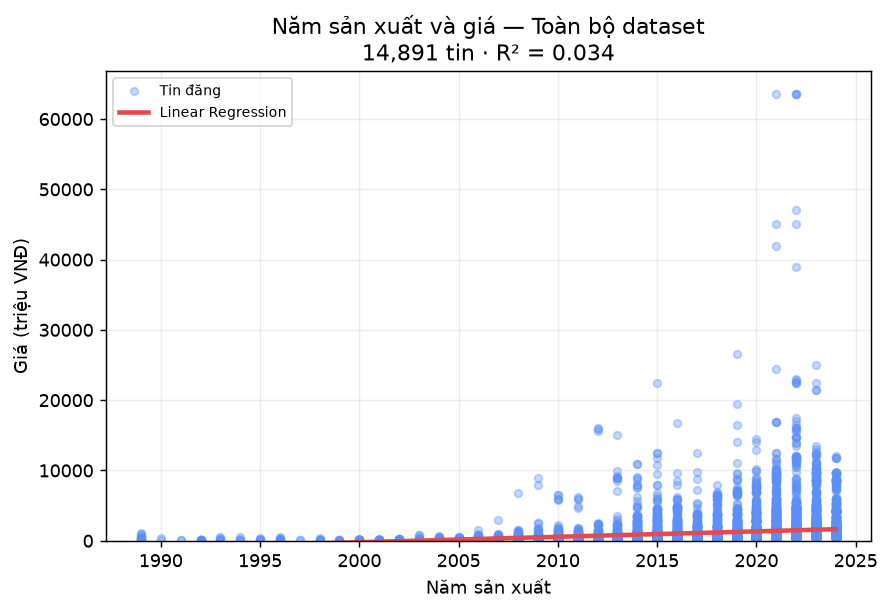

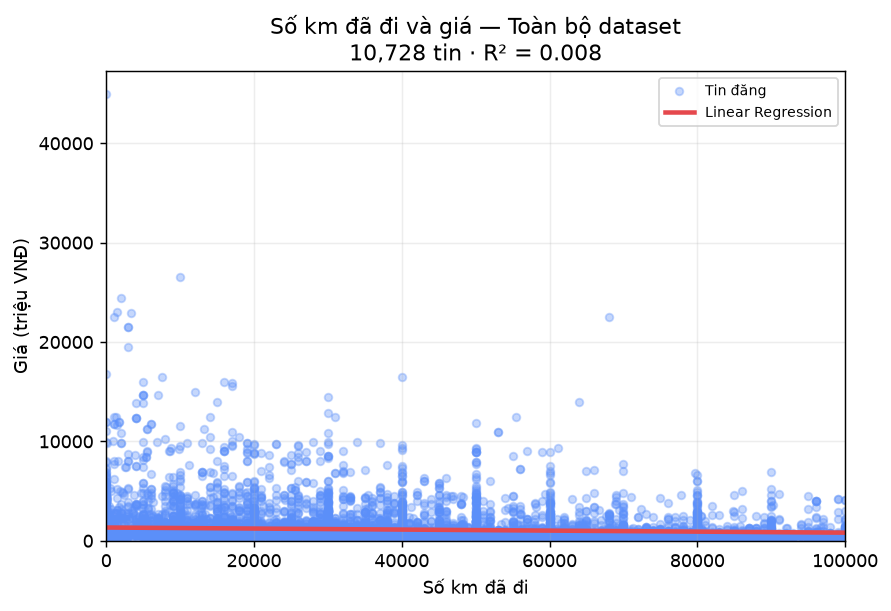

MSE: triệu²; RMSE: triệu VNĐ. Holdout 20% theo nhóm, khác cách chia từng dòng cũ.


,n,n_train,n_test,slope_all,r2_all,mse_test,rmse_test,r2_test,rmse_baseline,cv_train_r2_mean,cv_train_r2_std
year,14891.0,11848.0,3043.0,77.4088,0.0337,2.901288e+06,1703.3167,0.0466,1744.9175,0.0349,0.0158
km_capped_100k,10728.0,8582.0,2146.0,-0.0052,0.0083,2.842964e+06,1686.1091,0.0078,1692.7167,0.0074,0.0035


R² mô tả mọi km không âm: 0.000287 | n = 11898


In [12]:
from IPython.display import Image as IPyImage, display
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score

def show_figure(figure):
    # Backend Agg cần xuất PNG để lưu biểu đồ vào output notebook.
    if figure is None:
        print("Không đủ dữ liệu để vẽ biểu đồ.")
        return
    buffer = io.BytesIO()
    figure.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    plt.close(figure)
    display(IPyImage(data=buffer.getvalue()))

market, market_label = select_market(dataset, None)
empty_results = dataset.iloc[0:0]
show_figure(plot_year_regression(market, empty_results, market_label))
show_figure(plot_mileage_regression(market, empty_results, market_label))


def regression_report(frame, feature):
    if len(frame) < 30 or frame[feature].nunique() < 2:
        print(f"Không đủ quan sát để đánh giá hồi quy theo {feature}: n={len(frame)}.")
        return None
    X, y = frame[[feature]], frame["Price_Million"]
    # Tránh bản ghi cùng tên xe + giá xuất hiện cả train và test.
    groups = pd.util.hash_pandas_object(frame[["Name", "Price_Million"]], index=False)
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(splitter.split(X, y, groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))

    model = LinearRegression().fit(X_train, y_train)
    predictions = model.predict(X_test)
    baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
    mse = mean_squared_error(y_test, predictions)
    # Kiểm chéo chỉ trên train; test độc lập không dùng để chọn mô hình.
    folds = cross_val_score(
        LinearRegression(), X_train, y_train, groups=groups.iloc[train_idx],
        cv=GroupKFold(n_splits=5), scoring="r2",
    )
    descriptive = LinearRegression().fit(X, y)
    return {
        "n": len(frame), "n_train": len(train_idx), "n_test": len(test_idx),
        "slope_all": float(descriptive.coef_[0]),
        "r2_all": r2_score(y, descriptive.predict(X)),
        "mse_test": mse, "rmse_test": np.sqrt(mse),
        "r2_test": r2_score(y_test, predictions),
        "rmse_baseline": np.sqrt(mean_squared_error(y_test, baseline.predict(X_test))),
        "cv_train_r2_mean": folds.mean(), "cv_train_r2_std": folds.std(),
    }


year_col = find_column(market, ["Năm sản xuất"]) or "Năm sản xuất"
year_data = market[["Name", "Price_Million", year_col]].copy()
year_data["Year"] = pd.to_numeric(year_data[year_col], errors="coerce")
year_data = year_data.dropna(subset=["Year", "Price_Million"])
year_data = year_data[year_data["Year"].between(1900, 2035)]

mileage_col = find_column(market, ["Số Km đã đi", "Số km đã đi", "Km đã đi", "Mileage"]) or "Số Km đã đi"
mileage_data = market[["Name", "Price_Million", mileage_col]].copy()
mileage_data["Mileage"] = parse_mileage_series(mileage_data[mileage_col])
mileage_data = mileage_data.dropna(subset=["Mileage", "Price_Million"])
mileage_known = mileage_data[mileage_data["Mileage"].ge(0)]
mileage_capped = mileage_known[mileage_known["Mileage"].between(0, 100_000)]

regression_metrics = {
    "year": regression_report(year_data, "Year"),
    "km_capped_100k": regression_report(mileage_capped, "Mileage"),
    "km_all_non_negative": {
        "n": int(len(mileage_known)),
        "r2_all": (
            float(r2_score(
                mileage_known["Price_Million"],
                LinearRegression().fit(
                    mileage_known[["Mileage"]], mileage_known["Price_Million"]
                ).predict(mileage_known[["Mileage"]]),
            ))
            if len(mileage_known) >= 2 and mileage_known["Mileage"].nunique() >= 2
            else float("nan")
        ),
    },
}
print("MSE: triệu²; RMSE: triệu VNĐ. Holdout 20% theo nhóm, khác cách chia từng dòng cũ.")
scored = {
    key: value for key, value in regression_metrics.items()
    if key != "km_all_non_negative" and value
}
if scored:
    display(pd.DataFrame(scored).T.round(4))
else:
    print("Chưa đủ dữ liệu để lập bảng R² và RMSE.")
print("R² mô tả mọi km không âm:", round(regression_metrics["km_all_non_negative"]["r2_all"], 6),
      "| n =", regression_metrics["km_all_non_negative"]["n"])


## 7. Evaluate the CNN

**Purpose.** Read the quality of the trained MobileNetV2. This section does not retrain it or need an image.

**Input / output.** `labels.json`, `metrics.json`, and `history.json` become precision, recall, F1, and two charts.

**Steps.**
1. Call `ensure_cnn_artifacts()`. If metadata or `history.json` is missing, download the model bundle.
2. If downloading fails, print a manual link and skip the charts instead of stopping the whole notebook.
3. Read precision by matrix column and recall by row. Accuracy alone does not show which class was missed.
4. Draw row- and column-normalized matrices, then plot accuracy and loss by epoch.

**Reading the result.** Accuracy is about 97%, and balanced accuracy is only about one point lower. The test set has only the seven learned car groups. Images outside those groups are not covered by this score.

**Related weeks.** Week 4: track loss across epochs. Week 5: confusion matrices, precision, recall, and F1.


Đang tải model.keras ...
Đang tải labels.json ...
Đang tải meta.json ...
Đang tải metrics.json ...
Đang tải history.json ...
Artifact: mobilenetv2 | 224 px | 2,422,855 tham số | test loss 0.1119
Accuracy 97.05% | balanced accuracy 96.15% | macro-F1 96.54% | weighted-F1 97.03%


,Nhóm xe,Số ảnh test,Precision,Recall,F1
0,Audi,199,98.49%,98.49%,98.49%
1,Hyundai Creta,67,95.24%,89.55%,92.31%
2,Mahindra Scorpio,75,98.65%,97.33%,97.99%
3,Rolls Royce,74,98.59%,94.59%,96.55%
4,Maruti Suzuki Swift,102,97.00%,95.10%,96.04%
5,Tata Safari,106,94.59%,99.06%,96.77%
6,Toyota Innova,190,96.41%,98.95%,97.66%


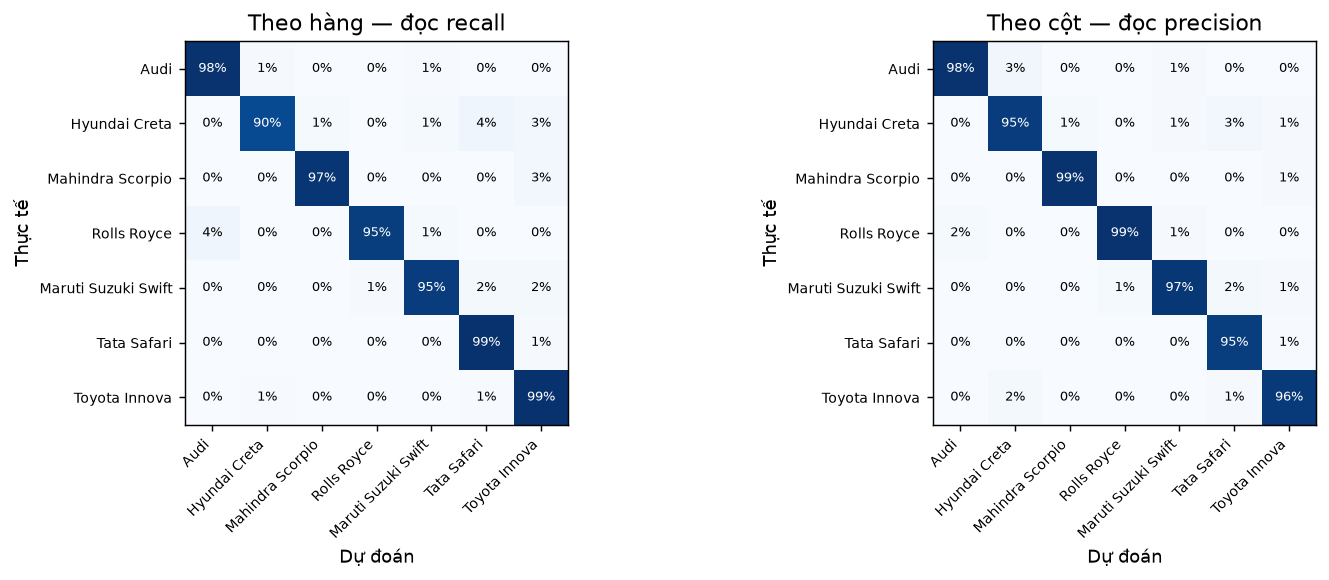

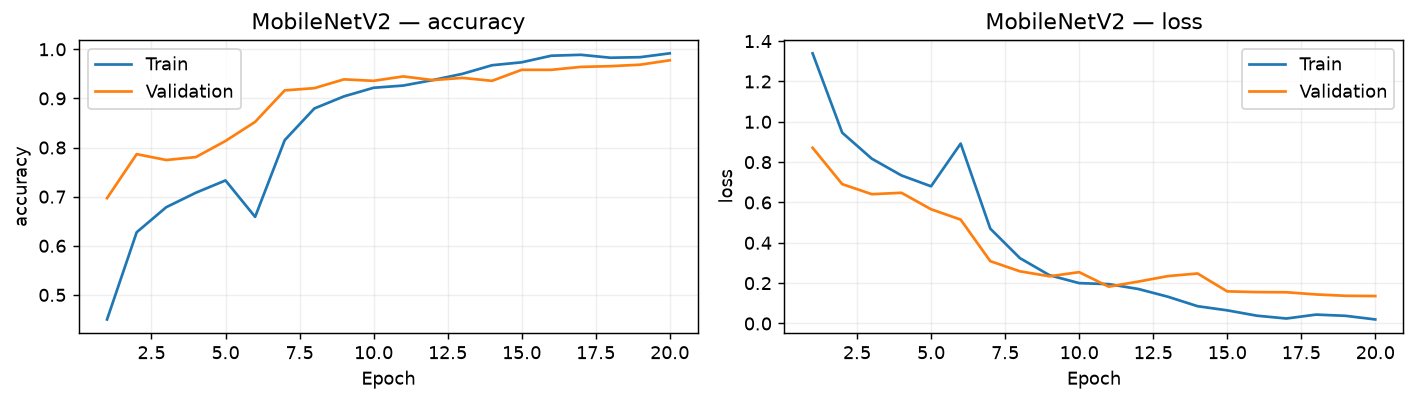

In [13]:
try:
    ensure_cnn_artifacts()
except Exception as error:
    print("Không tải được artifact CNN:", error)
    print(
        "Tải thủ công:",
        f"https://github.com/{CNN_ARTIFACT_REPOSITORY}/tree/{CNN_ARTIFACT_REF}/sources/CNN/outputs/car_cnn",
    )

# Chỉ cần metadata để đánh giá; chưa tải model.keras ở mục này.
# Nếu môi trường mới chưa có metadata, sẽ được tải kèm model ở mục 8.
cnn_meta = read_json(CNN_META_PATH, {})
cnn_labels = read_json(CNN_LABELS_PATH, {})
cnn_metrics = read_json(CNN_METRICS_PATH, {})
cnn_history = read_json(CNN_OUTPUT_DIR / "history.json", {})
if not cnn_metrics:
    print("Chưa có metadata CNN. Chạy mục 8 để tự tải bundle MobileNetV2 từ GitHub.")
else:
    class_names = cnn_labels.get("class_names") or cnn_meta.get("class_names")
    cm = np.asarray(cnn_metrics["confusion_matrix"], dtype=float)
    assert cm.shape == (len(class_names), len(class_names)), "Sai thứ tự / số lượng nhãn."


def safe_divide(numerator, denominator):
    return np.divide(numerator, denominator, out=np.zeros_like(numerator, dtype=float), where=denominator != 0)


if cnn_metrics:
    support, predicted = cm.sum(axis=1), cm.sum(axis=0)
    precision = safe_divide(np.diag(cm), predicted)
    recall = safe_divide(np.diag(cm), support)
    f1 = safe_divide(2 * precision * recall, precision + recall)
    per_class = pd.DataFrame({
        "Nhóm xe": class_names, "Số ảnh test": support.astype(int),
        "Precision": precision, "Recall": recall, "F1": f1,
    })
    print(f"Artifact: {cnn_metrics.get('architecture')} | {cnn_meta.get('image_size')} px | "
          f"{cnn_metrics.get('num_parameters'):,} tham số | test loss {cnn_metrics['test_loss']:.4f}")
    print(f"Accuracy {np.trace(cm) / cm.sum():.2%} | balanced accuracy {recall.mean():.2%} | "
          f"macro-F1 {f1.mean():.2%} | weighted-F1 {np.average(f1, weights=support):.2%}")
    display(per_class.style.format({"Precision": "{:.2%}", "Recall": "{:.2%}", "F1": "{:.2%}"}))

    # Hai cách chuẩn hóa để đọc precision / recall đúng chiều.
    row_normalized = safe_divide(cm, support[:, None])
    col_normalized = safe_divide(cm, predicted[None, :])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for ax, values, title in zip(axes, [row_normalized, col_normalized],
                                ["Theo hàng — đọc recall", "Theo cột — đọc precision"]):
        ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(len(class_names)), class_names, fontsize=8)
        ax.set(xlabel="Dự đoán", ylabel="Thực tế", title=title)
        for i, j in np.ndindex(cm.shape):
            ax.text(j, i, f"{values[i, j]:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if values[i, j] > 0.5 else "black")
    fig.tight_layout()
    show_figure(fig)

    # Hiển thị cả loss và accuracy, không chỉ nhìn accuracy của train.
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        for key, label in [(metric, "Train"), ("val_" + metric, "Validation")]:
            values = cnn_history.get(key, [])
            ax.plot(range(1, len(values) + 1), values, label=label)
        ax.set(xlabel="Epoch", ylabel=metric, title=f"MobileNetV2 — {metric}")
        ax.grid(alpha=0.2)
        ax.legend()
    fig.tight_layout()
    show_figure(fig)


## 8. CNN and transfer learning

**Purpose.** Explain how the image model is used. The code cell only defines the model-loading function.

**Input / output.** `model.keras`, labels, and `meta.json` become a Keras model, a list of seven classes, and image settings.

**Artifact processing steps.**
1. A $224\times224$ image passes through MobileNetV2 trained on ImageNet. Its original classifier is replaced with global average pooling, Dropout 0.30, Dense 128 with ReLU, Dropout 0.20, and Dense 7 with softmax.
2. For true label $y$ and softmax probability $p_y$, sparse categorical cross-entropy is $\mathcal{L}=-\log(p_y)$. Training used Adam.
3. Backpropagation computes gradients. Adam updates weights. The backbone BatchNorm keeps statistics estimated on ImageNet.
4. `load_cnn_bundle()` calls `ensure_cnn_artifacts()` and then `load_model`. There is no `fit` loop in the notebook or Streamlit app.
5. If TensorFlow is missing, the function gives a clear error. Text search does not use this function.

**Related week.** Week 4: convolution, pooling, ReLU, softmax, cross-entropy, Adam, and backpropagation.


In [14]:
# Model được nạp lúc cần. ensure_cnn_artifacts() ở mục 1 tải bundle nếu máy còn thiếu.
@st.cache_resource(show_spinner=False)
def load_cnn_bundle():
    """Lazy-load MobileNetV2. Notebook và ứng dụng đều không gọi fit."""
    ensure_cnn_artifacts()
    labels_data = read_json(CNN_LABELS_PATH, {})
    meta = read_json(CNN_META_PATH, {})
    labels = labels_data.get("class_names") or meta.get("class_names")
    if not labels:
        raise ValueError("Không tìm thấy class_names trong labels.json/meta.json.")
    try:
        import tensorflow as tf
    except ImportError as error:
        raise ImportError(
            "Chưa có TensorFlow nên không nạp được MobileNetV2. "
            "Phần tìm xe bằng văn bản vẫn chạy. Cài bằng: python -m pip install tensorflow"
        ) from error
    model = tf.keras.models.load_model(CNN_MODEL_PATH)
    return model, list(labels), meta


In [15]:
try:
    bootstrap_result = ensure_cnn_artifacts()
except Exception as error:
    bootstrap_result = {"downloaded": []}
    print(f"Không có artifact CNN ({type(error).__name__}: {error}). Tìm kiếm văn bản và hồi quy vẫn chạy.")
else:
    cnn_labels = read_json(CNN_LABELS_PATH, {})
    cnn_meta = read_json(CNN_META_PATH, {})
    class_names = cnn_labels.get("class_names") or cnn_meta.get("class_names") or []
    print("Model:", CNN_MODEL_PATH, "OK" if CNN_MODEL_PATH.is_file() else "THIẾU")
    print("Nhãn:", ", ".join(class_names))
    if bootstrap_result["downloaded"]:
        print("Đã tải từ GitHub:", ", ".join(bootstrap_result["downloaded"]))
print("App không gọi model.fit. Huấn luyện nằm ở sources/CNN/train_cnn.py.")


Model: /Users/andrewlap/PhD. MSE-AI/PPR501/Projects/PPR501-car-analysis/CNN/outputs/car_cnn/model.keras OK
Nhãn: Audi, Hyundai Creta, Mahindra Scorpio, Rolls Royce, Maruti Suzuki Swift, Tata Safari, Toyota Innova
App không gọi model.fit. Huấn luyện nằm ở sources/CNN/train_cnn.py.


## 9. Image inference and rejection threshold

**Purpose.** Run one image through the same app pipeline and see how a confidence threshold changes the answer.

**Input / output.** An RGB image becomes the top three softmax probabilities and one conclusion.

**Steps.**
1. If the test image is missing, download `Dataset/Test/Audi/1000.jpg` from the pinned commit. If the download fails, skip it without stopping the notebook.
2. Convert the image to RGB, resize it from `meta.json`, divide pixels by 255, and read softmax.
3. If the highest probability is below $\tau=0{,}60$, return `Không chắc chắn` instead of forcing a label.
4. The final table compares the same image at thresholds 0.30, 0.60, 0.90, and 0.9999.

**Reading the result.** A lower threshold rejects fewer images but can make more wrong labels. The 0.60 threshold is fixed; it was not chosen on validation data to maximize F1. One correct image does not replace the precision/recall table in section 7.

**Related weeks.** Week 4: softmax. Week 5: decision thresholds.


In [16]:
# Suy luận top-3 từ softmax của MobileNetV2.
def predict_car_image(image: Image.Image | None) -> dict[str, Any]:
    """Dự đoán top-3 trực tiếp từ đầu ra softmax của MobileNetV2."""
    if image is None:
        raise ValueError("Hãy chọn một ảnh xe trước khi nhận diện.")

    model, labels, meta = load_cnn_bundle()
    image_size = int(meta.get("image_size", 224))
    prepared = image.convert("RGB").resize((image_size, image_size))
    array = np.asarray(prepared, dtype=np.float32) / 255.0
    batch = np.expand_dims(array, axis=0)
    probabilities = model.predict(batch, verbose=0)[0]
    probability_map = {
        label: float(probabilities[index]) for index, label in enumerate(labels)
    }
    ranked = sorted(probability_map.items(), key=lambda item: item[1], reverse=True)
    best_label, best_score = ranked[0]
    uncertain = best_score < CNN_LOW_CONFIDENCE
    status = "uncertain" if uncertain else "recognized"
    conclusion = "Không chắc chắn" if uncertain else best_label

    return {
        "probabilities": probability_map,
        "ranked": ranked,
        "best_label": best_label,
        "best_score": best_score,
        "status": status,
        "conclusion": conclusion,
    }

def format_probability(probability: float) -> str:
    percent = probability * 100
    return "< 0.01%" if 0 < percent < 0.01 else f"{percent:.2f}%"


Chưa có ảnh test. Đang tải một ảnh mẫu...


,Lớp,Loại,Số tham số
0,mobilenetv2_1.00_224,Functional,2257984
1,dropout,Dropout,0
2,dense,Dense,163968
3,dropout_1,Dropout,0
4,predictions,Dense,903


Ảnh: Dataset/Test/Audi/1000.jpg | thư mục lớp: Audi
Kết luận: Audi | 99.98%


,Lớp,Softmax
0,Audi,9.998333e-01
1,Rolls Royce,1.662848e-04
2,Hyundai Creta,1.919193e-07


,Ngưỡng,Trạng thái
0,0.3000,Chấp nhận
1,0.6000,Chấp nhận
2,0.9000,Chấp nhận
3,0.9999,Từ chối / chưa chắc


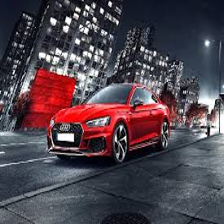

In [17]:
try:
    import tensorflow  # noqa: F401
    tensorflow_ready = True
except Exception as error:
    tensorflow_ready = False
    print("Không nạp được TensorFlow. Bỏ qua dự đoán ảnh:", type(error).__name__, error)

sample_path = ensure_sample_image()
if not tensorflow_ready:
    print("Mục nhận diện ảnh cần TensorFlow. Các mục văn bản và hồi quy không phụ thuộc phần này.")
elif not CNN_MODEL_PATH.is_file():
    print("Chưa có model CNN. Metrics ở mục 7 vẫn đọc được nếu metadata đã tải.")
elif sample_path is None:
    print("Không có ảnh test và không tải được ảnh mẫu.")
else:
    try:
        model, labels, meta = load_cnn_bundle()
        display(pd.DataFrame([
            {"Lớp": layer.name, "Loại": type(layer).__name__, "Số tham số": layer.count_params()}
            for layer in model.layers
        ]))
        with Image.open(sample_path) as opened:
            sample = opened.convert("RGB")
        prediction = predict_car_image(sample)
        assert np.isclose(sum(prediction["probabilities"].values()), 1.0, atol=1e-5)
        print("Ảnh:", sample_path.relative_to(SOURCES_DIR), "| thư mục lớp:", sample_path.parent.name)
        print("Kết luận:", prediction["conclusion"], "|", format_probability(prediction["best_score"]))
        display(pd.DataFrame(prediction["ranked"][:3], columns=["Lớp", "Softmax"]))
        display(pd.DataFrame([
            {"Ngưỡng": threshold,
             "Trạng thái": "Chấp nhận" if prediction["best_score"] >= threshold else "Từ chối / chưa chắc"}
            for threshold in (0.3, CNN_LOW_CONFIDENCE, 0.9, 0.9999)
        ]))
        display(sample.resize((224, 224)))
    except Exception as error:
        print("Dự đoán ảnh không chạy được:", type(error).__name__, error)
        print("Phần tìm xe bằng văn bản vẫn dùng được.")


## 10. Appendix — standalone Streamlit interface

This section contains the full standalone Streamlit UI source in the next Python cell, tagged `app-ui`. It is plain Python, without compressed or encoded strings.

The helper below reads the current notebook directly, regardless of its file name. It joins the `app-core` cells (data processing, TF-IDF, MiniLM, CNN, and OLS) with the `app-ui` cell in order, checks syntax, and creates `_chatbot_streamlit_runtime.py` next to the notebook. The app finds its CSV, cache, and model folders itself; it needs no external Python source file.


In [18]:
# Giao diện Streamlit độc lập (tag app-ui), hiển thị toàn bộ mã nguồn Python trực tiếp.
# Hàm xử lý dữ liệu nằm ở các cell app-core, không viết lại ở đây.

def _warm_dataset(state: dict[str, Any], progress) -> None:
    started = time.perf_counter()
    st.write("Đọc dữ liệu")
    load_dataset()
    progress.progress(0.2, text="Tạo chỉ mục TF-IDF")
    st.write("Tạo chỉ mục TF-IDF")
    build_tfidf_index()
    elapsed = round(time.perf_counter() - started, 2)
    state["seconds"]["dataset_tfidf"] = elapsed
    LOGGER.info("warm-up dataset+tfidf %.2fs", elapsed)
    progress.progress(0.4, text="Tải MiniLM")


def _warm_text_model(state: dict[str, Any], progress) -> None:
    started = time.perf_counter()
    st.write("Tải MiniLM")
    try:
        load_or_build_embeddings(MODEL_NAME)
        load_text_model(MODEL_NAME)
        encode_query("khởi động", MODEL_NAME)
        state["device"] = resolve_embedding_device()
        state["text"] = "ready"
        state["text_warning"] = None
    except Exception as error:
        LOGGER.exception("Không chuẩn bị được pipeline semantic")
        state["text"] = "failed"
        warning = (
            f"Không tải được `{MODEL_NAME}` ({type(error).__name__}) — đang dùng TF-IDF."
        )
        state["text_warning"] = warning
        SEMANTIC_FAILURE.update(model=MODEL_NAME, warning=warning)
    elapsed = round(time.perf_counter() - started, 2)
    state["seconds"]["text_model"] = elapsed
    LOGGER.info("warm-up text %.2fs status=%s", elapsed, state["text"])
    progress.progress(0.7, text="Tải MobileNetV2")


def _warm_cnn(state: dict[str, Any], progress) -> None:
    started = time.perf_counter()
    st.write("Tải MobileNetV2")
    try:
        model, _labels, meta = load_cnn_bundle()
        image_size = int(meta.get("image_size", 224))
        dummy = np.zeros((1, image_size, image_size, 3), dtype=np.float32)
        model.predict(dummy, verbose=0)
        state["cnn"] = "ready"
        state["cnn_error"] = None
    except Exception as error:
        LOGGER.exception("Không chuẩn bị được CNN")
        state["cnn"] = f"failed: {type(error).__name__}"
        state["cnn_error"] = (
            f"Không tải được MobileNetV2 ({type(error).__name__}). "
            "Trang tìm xe vẫn dùng được."
        )
    elapsed = round(time.perf_counter() - started, 2)
    state["seconds"]["cnn"] = elapsed
    LOGGER.info("warm-up cnn %.2fs status=%s", elapsed, state["cnn"])
    progress.progress(0.95, text="Hoàn tất")


def warm_up_resources() -> dict[str, Any]:
    """Nạp dataset, TF-IDF, MiniLM và MobileNetV2 trong process hiện tại."""
    state = get_readiness()
    if state.get("ready"):
        return state

    progress = st.progress(0, text="Đọc dữ liệu")
    started = time.perf_counter()
    with st.status("Đang chuẩn bị tài nguyên tìm kiếm và nhận diện…", expanded=True) as status:
        try:
            _warm_dataset(state, progress)
            _warm_text_model(state, progress)
            _warm_cnn(state, progress)
        except Exception as error:
            LOGGER.exception("Warm-up dừng sớm")
            if state.get("text") == "pending":
                state["text"] = "failed"
                state["text_warning"] = f"{type(error).__name__}: {error}"
            if state.get("cnn") == "pending":
                state["cnn"] = f"failed: {type(error).__name__}"
                state["cnn_error"] = (
                    f"Không tải được MobileNetV2 ({type(error).__name__}). "
                    "Trang tìm xe vẫn dùng được."
                )
            st.error(f"Khởi động chưa hoàn tất: {type(error).__name__}: {error}")
        state["seconds"]["total"] = round(time.perf_counter() - started, 2)
        state["ready"] = True
        LOGGER.info("warm-up total %.2fs %s", state["seconds"]["total"], state["seconds"])
        progress.progress(1.0, text="Đã sẵn sàng")
        status.update(label="Đã sẵn sàng.", state="complete", expanded=False)
    return state


def render_warmup_screen() -> None:
    """Màn hình chặn cho đến khi warm-up kết thúc, kể cả khi một model lỗi."""
    render_html(
        '<section class="welcome"><div class="eyebrow">Đang khởi động</div>'
        "<h2>Đang chuẩn bị mô hình…</h2>"
        "<p>Lần đầu sau khi mở app, hệ thống cần đọc dữ liệu và tải model. "
        "Các lần truy cập sau sẽ vào ngay.</p></section>"
    )
    warm_up_resources()


def format_probability(probability: float) -> str:
    percent = probability * 100
    return "< 0.01%" if 0 < percent < 0.01 else f"{percent:.2f}%"


def figure_to_png(figure: Any) -> bytes | None:
    """Lưu biểu đồ vào bộ nhớ phiên, không ghi file PNG tạm."""
    if figure is None:
        return None
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    plt.close(figure)
    return buffer.getvalue()


def format_value(value: Any) -> str:
    if pd.isna(value):
        return "N/A"
    if isinstance(value, float) and value.is_integer():
        return str(int(value))
    return str(value)


def format_spec(value: Any, field: str) -> str:
    """Chuẩn hóa giá trị cho UI mà không thay đổi dữ liệu nguồn."""
    if not known_value(value, field):
        return "Chưa có dữ liệu"
    if field == "Số Km đã đi":
        km = parse_mileage(value)
        return f"{km:,.0f} km".replace(",", ".") if np.isfinite(km) else "Chưa có dữ liệu"
    if field == "Tình trạng":
        return "Đã qua sử dụng" if normalize_text(value) in {"xe cu", "xe da dung", "da qua su dung"} else str(value).strip()
    if field == "_Km":
        return f"{float(value):,.0f} km".replace(",", ".")
    if field == "Price_Million":
        return f"{float(value):,.0f} triệu".replace(",", ".")
    return re.sub(r"\s+", " ", format_value(value)).strip()


def car_records(results: pd.DataFrame) -> list[dict[str, Any]]:
    """Lưu đủ thông số và đối chiếu tiêu chí gốc, kể cả sau khi nới bộ lọc."""
    if results.empty:
        return []

    name_col = find_column(results, ["Name", "Tên xe", "Dòng xe", "Model", "Hãng xe"])
    detail_labels = [
        "Năm sản xuất", "Tình trạng", "Số Km đã đi", "Xuất xứ", "Kiểu dáng",
        "Hộp số", "Động cơ", "Màu ngoại thất", "Màu nội thất", "Số chỗ ngồi", "Số cửa", "Location",
    ]
    criteria = results.attrs.get("criteria", [])
    evaluations = [
        (criterion, criterion_values(results, criterion)) for criterion in criteria
    ]
    masks = [criterion_mask(values, criterion) for criterion, values in evaluations]
    records = []
    for number, (index, car) in enumerate(results.iterrows(), start=1):
        details = [
            (label, format_spec(car.get(find_column(results, [label]) or label), label))
            for label in detail_labels
        ]
        states = []
        for (criterion, values), mask in zip(evaluations, masks):
            field = criterion["field"]
            state = "unknown" if pd.isna(values.loc[index]) else "matched" if mask.loc[index] else "unmatched"
            states.append({
                "field": field, "label": criterion["label"], "state": state,
                "actual": format_spec(car.get(field), field),
            })
        link = car.get("Link")
        semantic = car.get("_SemanticScore")
        records.append(
            {
                "number": number,
                "name": format_value(car.get(name_col)) if name_col else f"Xe #{number}",
                "price": float(car["Price_Million"]),
                "details": details,
                "condition": dict(details)["Tình trạng"],
                "listing_code": (
                    re.sub(r"(?i)^mã\s*:\s*", "", str(car["Car_code"]).strip()).strip() or None
                    if known_value(car.get("Car_code")) else None
                ),
                "description": str(car["Description"]).strip() if known_value(car.get("Description")) else None,
                "criteria_states": states,
                **{state: [item["field"] for item in states if item["state"] == state]
                   for state in ("matched", "unmatched", "unknown")},
                "semantic": None if pd.isna(semantic) else float(semantic),
                "tfidf": float(car["_TfidfScore"]),
                "score": float(car["_RetrievalScore"]),
                "link": (
                    str(link)
                    if pd.notna(link) and str(link).startswith(("http://", "https://"))
                    else None
                ),
            }
        )
    return records


@st.cache_data(show_spinner=False)
def regression_pngs(
    fingerprint: str,
    brand: str | None,
    row_ids: tuple[int, ...],
) -> tuple[bytes | None, bytes | None]:
    """Vẽ hai biểu đồ giá; cache theo fingerprint, hãng và danh sách xe."""
    del fingerprint
    dataset = load_dataset()
    market, market_label = select_market(dataset, brand)
    if row_ids:
        wanted = set(row_ids)
        results = dataset[dataset["_row_id"].isin(wanted)].copy()
    else:
        results = dataset.iloc[0:0].copy()
    return (
        figure_to_png(plot_year_regression(market, results, market_label)),
        figure_to_png(plot_mileage_regression(market, results, market_label)),
    )


def _save_turn_charts(
    turn_key: str,
    year_png: bytes | None,
    mileage_png: bytes | None,
) -> None:
    messages = st.session_state.get("messages") or []
    try:
        index = int(turn_key)
    except (TypeError, ValueError):
        return
    if not 0 <= index < len(messages):
        return
    search = messages[index].get("search")
    if not isinstance(search, dict):
        return
    search["year_png"] = year_png
    search["mileage_png"] = mileage_png
    search["charts_requested"] = True


def build_search_turn(
    text: str,
    retrieval_mode: str,
    semantic_weight: float,
    top_k: int,
) -> dict[str, Any]:
    """Tính một lượt trả lời tìm xe từ văn bản."""
    search = None
    search_error = None
    try:
        dataset = load_dataset()
        results, brand, minimum, maximum = recommend_cars(
            text,
            dataset,
            retrieval_mode=retrieval_mode,
            semantic_weight=semantic_weight,
            top_k=int(top_k),
        )
        row_ids = (
            [int(value) for value in results["_row_id"].tolist()]
            if not results.empty
            else []
        )
        search = {
            "empty": bool(results.empty),
            "message": results.attrs.get("fallback_message"),
            "mode": results.attrs.get("retrieval_mode", retrieval_mode),
            "warning": results.attrs.get("semantic_warning"),
            "minimum": minimum,
            "maximum": maximum,
            "cars": car_records(results),
            "criteria": results.attrs.get("criteria", []),
            "relaxed": results.attrs.get("relaxed", []),
            "brand": None if brand is None else str(brand),
            "row_ids": row_ids,
            "year_png": None,
            "mileage_png": None,
        }
    except Exception as error:
        LOGGER.exception("Car search failed")
        search_error = f"{type(error).__name__}: {error}"
    return {"role": "assistant", "search": search, "search_error": search_error}


EXAMPLES = (
    "Toyota 7 chỗ dưới 900 triệu",
    "SUV gia đình đời 2020",
    "Hyundai cũ dưới 700 triệu",
)
EXAMPLE_QUERIES = {
    "Toyota 7 chỗ dưới 900 triệu": "Tìm Toyota 7 chỗ dưới 900 triệu",
    "SUV gia đình đời 2020": "Xe SUV cho gia đình, đời 2020",
    "Hyundai cũ dưới 700 triệu": "Tìm xe Hyundai đã qua sử dụng dưới 700 triệu",
}
CAR_HIGHLIGHTS = ("Năm sản xuất", "Số Km đã đi", "Số chỗ ngồi", "Kiểu dáng")
DETAIL_ICONS = {
    "Năm sản xuất": "calendar_month",
    "Số Km đã đi": "speed",
    "Số chỗ ngồi": "airline_seat_recline_normal",
    "Kiểu dáng": "directions_car",
    "Location": "location_on",
    "Hộp số": "gearbox",
    "Động cơ": "local_gas_station",
    "Tình trạng": "verified",
    "Xuất xứ": "public",
    "Màu ngoại thất": "palette",
    "Màu nội thất": "interior",
    "Số cửa": "door",
}
VISION_PAGE: Any = None

ICON_PATHS = {
    "car": '<path d="m5 10 1.5-5h11L19 10M4 10h16v8H4zM7 14h2m6 0h2M6 18v2m12-2v2"/>',
    "search": '<circle cx="10.5" cy="10.5" r="6.5"/><path d="m16 16 4 4"/>',
    "chart": '<path d="M4 4v16h16M8 15l4-5 4 2 4-7"/>',
    "camera": '<path d="M4 7h4l2-3h4l2 3h4v13H4z"/><circle cx="12" cy="13" r="4"/>',
    "calendar_month": '<rect x="4" y="5" width="16" height="15" rx="2"/><path d="M8 3v4m8-4v4M4 10h16m-11 4h1m4 0h1m-6 3h1"/>',
    "speed": '<path d="M4 19a9 9 0 1 1 16 0M12 13l5-5M7 10l1 1m-1 5H5m14 0h-2M12 5v2"/><circle cx="12" cy="14" r="2"/>',
    "airline_seat_recline_normal": '<path d="M6 4v10a3 3 0 0 0 3 3h9M9 8v6h7v6M6 20h12"/><circle cx="10" cy="4" r="2"/>',
    "directions_car": '<path d="m5 10 2-5h10l2 5M4 10h16v8H4zM7 14h2m6 0h2M6 18v2m12-2v2"/>',
    "location_on": '<path d="M19 10c0 5-7 11-7 11S5 15 5 10a7 7 0 1 1 14 0Z"/><circle cx="12" cy="10" r="2.5"/>',
    "local_gas_station": '<path d="M4 21V4h10v17M3 21h13M7 7h4v5H7zM14 13h3v5a2 2 0 0 0 4 0V8l-3-3m1 1-2 2 3 3"/>',
    "verified": '<path d="m12 3 8 3v6c0 5-8 9-8 9s-8-4-8-9V6zM8 12l3 3 5-6"/>',
    "public": '<circle cx="12" cy="12" r="9"/><ellipse cx="12" cy="12" rx="4" ry="9"/><path d="M3 12h18"/>',
    "palette": '<circle cx="12" cy="12" r="9"/><path d="M12 3v18M3 12h18"/>',
    "gearbox": '<path d="M6 4v12a3 3 0 0 0 6 0V4m0 6h6V4M6 10h6"/><circle cx="6" cy="3" r="1"/><circle cx="12" cy="3" r="1"/><circle cx="18" cy="3" r="1"/>',
    "interior": '<path d="M7 4v9a3 3 0 0 0 3 3h8v4M7 20h11M10 8h6v8M4 20h3"/>',
    "door": '<path d="M5 21V9l6-6h8v18zM8 10l4-4h4v6H8zM15 16h2"/>',
    "check": '<path d="m5 12 4 4L19 6"/>',
    "mismatch": '<path d="m6 6 12 12M18 6 6 18"/>',
    "unknown": '<circle cx="12" cy="12" r="9"/><path d="M9.5 9a2.5 2.5 0 0 1 5 .5c0 1.5-2.5 2-2.5 3.5m0 3h.01"/>',
}


def ui_icon(name: str) -> str:
    """SVG nét đồng nhất, chỉ sử dụng các path cố định."""
    return (
        '<svg class="ui-icon" viewBox="0 0 24 24" fill="none" '
        'stroke="currentColor" stroke-width="1.6" stroke-linecap="round" '
        f'stroke-linejoin="round" aria-hidden="true">{ICON_PATHS.get(name, ICON_PATHS["car"])}</svg>'
    )


APP_CSS = """
<style>
.stApp {
  --auto-ink: light-dark(#152b3b, #e4edf2);
  --auto-muted: light-dark(#647788, #9aafb9);
  --auto-accent: light-dark(#087f8c, #6dd4cb);
  --auto-soft: light-dark(#e9f5f5, #16353e);
  --auto-surface: light-dark(#ffffff, #13252f);
  --auto-bg: light-dark(#f5f7fa, #0e1c25);
  --auto-line: light-dark(#e0e7ed, #2a414e);
  --auto-mismatch-bg: light-dark(#fff5ec, #392a20);
  --auto-mismatch-line: light-dark(#c97c3f, #d49a6f);
  --auto-mismatch-ink: light-dark(#8b4616, #f3bf97);
  --auto-shadow: light-dark(#152b3b0d, #00000066);
  background: var(--auto-bg); color: var(--auto-ink);
}
[data-testid="stHeader"] {background: var(--auto-surface); border-bottom: 1px solid var(--auto-line);}
[data-testid="stMainBlockContainer"] {max-width: 1120px; padding: 3.5rem 2.5rem 7rem;}
[data-testid="stSidebar"] {background: var(--auto-surface); border-right: 1px solid var(--auto-line);}
[data-testid="stSidebarUserContent"] {padding-top: 1.5rem;}
[data-testid="stTopNav"] a {border-radius: 8px;}
[data-testid="stTopNav"] a[aria-current="page"] {background: var(--auto-soft); color: var(--auto-accent);}
.ui-icon {width: 20px; height: 20px; flex-shrink: 0; vertical-align: middle;}
.brand {display: flex; align-items: center; gap: 11px; padding-bottom: 22px; border-bottom: 1px solid var(--auto-line); margin-bottom: 20px;}
.brand-mark {width: 42px; height: 42px; border-radius: 12px; display: grid; place-items: center; background: light-dark(#152b3b, #1c4a56); color: #7dd3cf;}
.brand-mark .ui-icon {width: 27px; height: 27px;}
.brand-name {font-size: 1.12rem; font-weight: 750; letter-spacing: -.6px;}
.brand-sub {color: var(--auto-muted); font-size: .72rem; letter-spacing: 1.5px; text-transform: uppercase;}
.sidebar-label, .section-label {color: var(--auto-muted); font-size: .69rem; letter-spacing: 1.6px; font-weight: 650; text-transform: uppercase; margin: 0 0 12px;}
.workspace {display: flex; align-items: center; gap: 10px; background: var(--auto-soft); border: 1px solid var(--auto-line); border-radius: 10px; padding: 12px; color: var(--auto-accent); font-size: .88rem; font-weight: 600; margin-bottom: 18px;}
.sidebar-note {margin-top: 20px; padding-top: 18px; border-top: 1px solid var(--auto-line); font-size: .76rem; color: var(--auto-muted); line-height: 1.7;}
.sidebar-note strong {color: var(--auto-ink); font-weight: 600;}
.page-hero {display: flex; justify-content: space-between; align-items: center; gap: 24px; padding: 4px 0 24px; margin-bottom: 12px; border-bottom: 1px solid var(--auto-line);}
.page-hero h1 {font-size: clamp(1.65rem, 2.8vw, 2.15rem); font-weight: 720; letter-spacing: -.9px; line-height: 1.22; color: var(--auto-ink); margin: 6px 0 10px; padding: 0;}
.page-hero p {font-size: .9rem; color: var(--auto-muted); line-height: 1.65; margin: 0; max-width: 560px;}
.eyebrow {font-size: .68rem; font-weight: 650; letter-spacing: 2px; color: var(--auto-accent); text-transform: uppercase;}
.hero-emblem {display: flex; align-items: center; gap: 9px; border: 1px solid var(--auto-line); background: var(--auto-surface); border-radius: 30px; padding: 10px 14px; white-space: nowrap; font-size: .73rem; color: var(--auto-muted);}
.hero-emblem .ui-icon {color: var(--auto-accent); width: 18px; height: 18px;}
.welcome {position: relative; overflow: hidden; border-radius: 18px; padding: 32px; background: linear-gradient(115deg,#152b3b,#1f4855); color: #fff; margin: 8px 0 20px;}
.welcome:after {content: ""; position: absolute; width: 270px; height: 270px; right: -80px; top: -140px; border: 1px solid #ffffff18; border-radius: 50%; box-shadow: 0 0 0 38px #ffffff05, 0 0 0 76px #ffffff04; pointer-events: none;}
.welcome h2 {font-size: 1.65rem; font-weight: 650; letter-spacing: -.6px; color: #fff; margin: 12px 0; padding: 0;}
.welcome p {font-size: .9rem; color: #b8cdd5; margin: 0; max-width: 490px; line-height: 1.8;}
.welcome .eyebrow {color: #87d5cf;}
.feature-grid {display: grid; grid-template-columns: repeat(3,minmax(0,1fr)); gap: 14px; margin: 0 0 20px;}
.feature {background: var(--auto-surface); border: 1px solid var(--auto-line); border-radius: 13px; padding: 20px;}
.feature-icon {display: inline-grid; place-items: center; width: 36px; height: 36px; background: var(--auto-soft); color: var(--auto-accent); border-radius: 10px; margin-bottom: 12px;}
.feature h3 {font-size: .9rem; font-weight: 650; padding: 0; margin: 0 0 7px; color: var(--auto-ink);}
.feature p {font-size: .78rem; color: var(--auto-muted); line-height: 1.65; margin: 0;}
.suggestion-heading {font-size: .8rem; font-weight: 650; color: var(--auto-muted); margin: 4px 0 0;}
[data-testid="stChatMessage"] {background: transparent; border-radius: 0; padding: 8px 0; gap: 12px;}
[data-testid="stChatMessageAvatarAssistant"] {background: light-dark(#152b3b, #1c3d48); color: #8fdbd6; border-radius: 10px;}
[data-testid="stChatMessageAvatarUser"] {background: var(--auto-line); color: var(--auto-ink); border-radius: 10px;}
[data-testid="stChatMessageContent"] {min-width: 0;}
.query-bubble {display: inline-block; padding: 12px 17px; border: 1px solid var(--auto-line); border-radius: 4px 14px 14px; background: var(--auto-surface); font-size: .93rem; line-height: 1.6; white-space: pre-wrap; overflow-wrap: anywhere;}
.result-heading {display: flex; justify-content: space-between; align-items: center; gap: 16px; margin: 0 0 13px; padding-top: 4px;}
.result-heading h2 {font-size: 1rem; letter-spacing: -.25px; padding: 0; margin: 0; color: var(--auto-ink); font-weight: 650;}
.result-heading p {font-size: .75rem; color: var(--auto-muted); margin: 5px 0 0;}
.result-count {font-size: .74rem; background: var(--auto-soft); color: var(--auto-accent); padding: 6px 10px; border-radius: 7px; white-space: nowrap;}
.requested-criteria {margin: 0 0 16px; padding: 12px 14px; border: 1px solid var(--auto-line); border-radius: 12px; background: var(--auto-surface);}
.requested-criteria h3 {font-size: .78rem; font-weight: 650; margin: 0 0 9px; padding: 0; color: var(--auto-ink);}
.criteria-chips, .match-chips {display: flex; flex-wrap: wrap; align-items: center; gap: 6px; margin: 0; padding: 0; min-width: 0;}
.criterion-chip, .match-chip {display: inline-flex; align-items: center; gap: 5px; max-width: 100%; padding: 4px 8px; border: 1px solid var(--auto-line); border-radius: 7px; background: var(--auto-bg); color: var(--auto-ink); font-size: .72rem; line-height: 1.4; overflow-wrap: anywhere;}
[class*="st-key-car-card-"] {container: car-card / inline-size; background: var(--auto-surface); border: 1px solid var(--auto-line); border-radius: 16px; padding: 20px; box-shadow: 0 3px 14px var(--auto-shadow);}
[class*="st-key-car-card-"]:hover {border-color: var(--auto-accent);}
.listing-head {display: grid; grid-template-columns: minmax(0,1fr) auto; align-items: start; gap: 20px;}
.listing-identity {display: flex; align-items: flex-start; gap: 12px; min-width: 0;}
.listing-title {min-width: 0;}
.listing-rank {flex-shrink: 0; width: 32px; height: 32px; display: grid; place-items: center; border: 1px solid var(--auto-line); border-radius: 9px; color: var(--auto-muted); font-size: .72rem; font-weight: 600;}
.listing-identity h3 {font-size: 1.1rem; font-weight: 700; line-height: 1.45; letter-spacing: -.2px; margin: 0; padding: 0; color: var(--auto-ink); overflow-wrap: anywhere;}
.listing-meta {display: flex; flex-wrap: wrap; align-items: center; gap: 7px 12px; margin-top: 7px;}
.listing-location {display: inline-flex; flex-wrap: wrap; align-items: center; gap: 4px; max-width: 100%; font-size: .77rem; color: var(--auto-muted); overflow-wrap: anywhere;}
.listing-location .ui-icon, .condition-badge .ui-icon {width: 15px; height: 15px;}
.condition-badge {display: inline-flex; flex-wrap: wrap; align-items: center; gap: 5px; max-width: 100%; padding: 4px 8px; border: 1px solid var(--auto-line); border-radius: 6px; color: var(--auto-ink); background: var(--auto-bg); font-size: .72rem; line-height: 1.5; overflow-wrap: anywhere;}
.listing-price {display: flex; flex-direction: column; align-items: flex-end; text-align: right; max-width: 230px; min-width: 0;}
.listing-price small {display: block; font-size: .67rem; color: var(--auto-muted); margin-bottom: 3px;}
.listing-price strong {display: block; font-size: clamp(1.45rem, 3cqi, 1.8rem); font-weight: 750; letter-spacing: -.6px; line-height: 1.3; color: var(--auto-accent); overflow-wrap: anywhere;}
.spec-grid {display: grid; grid-template-columns: repeat(4,minmax(0,1fr)); gap: 10px; margin: 14px 0 16px; padding: 14px 0; border-top: 1px solid var(--auto-line); border-bottom: 1px solid var(--auto-line);}
.spec {display: flex; align-items: flex-start; gap: 8px; min-width: 0; padding: 4px 2px; border: 1px solid transparent; border-radius: 8px;}
.spec > div {display: flex; flex-wrap: wrap; align-items: center; column-gap: 6px; min-width: 0;}
.spec .ui-icon {width: 16px; height: 16px; color: var(--auto-muted); margin-top: 2px;}
.spec small {flex: 1 0 100%; color: var(--auto-muted); font-size: .75rem; line-height: 1.4; margin-bottom: 2px;}
.spec b {min-width: 0; font-size: .875rem; color: var(--auto-ink); font-weight: 650; overflow-wrap: anywhere;}
.listing-detail-groups {display: grid; grid-template-columns: repeat(auto-fit,minmax(min(100%,245px),1fr)); gap: 14px 26px;}
.listing-detail-group h4 {font-size: .7rem; letter-spacing: .7px; text-transform: uppercase; color: var(--auto-muted); font-weight: 650; margin: 0 0 7px; padding: 0;}
.listing-details {margin: 0;}
.detail-row {display: grid; grid-template-columns: minmax(0,1fr) minmax(0,1fr); gap: 8px; padding: 8px; border: 1px solid transparent; border-bottom-color: var(--auto-line); border-radius: 5px;}
.detail-row dt, .detail-row dd, .listing-detail-group, .listing-details {min-width: 0;}
.detail-row dt {display: flex; align-items: flex-start; gap: 6px; color: var(--auto-muted); font-size: .75rem; font-weight: 400; overflow-wrap: anywhere;}
.detail-row dt .ui-icon {width: 15px; height: 15px; margin-top: 1px;}
.detail-row dd {display: flex; flex-wrap: wrap; justify-content: flex-end; align-items: center; gap: 2px 6px; margin: 0; min-width: 0; color: var(--auto-ink); font-size: .875rem; font-weight: 600; text-align: right; overflow-wrap: anywhere;}
.detail-row dd > span, .listing-location > span, .condition-badge > span {min-width: 0; max-width: 100%; overflow-wrap: anywhere;}
.spec b.has-unmatched, .detail-row dd.has-unmatched > span:not(.state-mark),
.listing-location.has-unmatched > span:not(.state-mark), .condition-badge.has-unmatched > span:not(.state-mark),
.listing-price.has-unmatched strong {color: var(--auto-mismatch-ink);}
.listing-matches {margin: 12px 0 2px;}
.match-row {display: flex; flex-wrap: wrap; align-items: center; gap: 8px 12px;}
.match-summary {margin: 0; font-size: .78rem; line-height: 1.45; color: var(--auto-muted);}
.match-summary strong {color: var(--auto-ink); font-weight: 650;}
.match-summary.has-mismatch, .match-summary.has-mismatch strong {color: var(--auto-mismatch-ink);}
.match-note {flex-basis: 100%; margin: 0; color: var(--auto-muted); font-size: .75rem; line-height: 1.5; overflow-wrap: anywhere;}
.match-chip .ui-icon {width: 13px; height: 13px;}
.match-chip.matched {background: var(--auto-soft); border-color: var(--auto-accent); color: var(--auto-accent);}
.spec b.is-missing, .detail-row dd.is-missing, .condition-badge.is-missing, .listing-location.is-missing {color: var(--auto-muted); font-weight: 500;}
.state-mark {display: inline-flex; align-items: center; gap: 3px; font-size: .68rem; font-weight: 650; line-height: 1.2; white-space: nowrap;}
.state-mark .ui-icon {width: 13px; height: 13px;}
.state-mark.matched {color: var(--auto-accent);}
.state-mark.unmatched {color: var(--auto-mismatch-ink);}
.state-mark.unknown {color: var(--auto-muted);}
.listing-price .state-mark {margin-top: 4px;}
.listing-description {white-space: pre-wrap; overflow-wrap: anywhere; font-size: .82rem; line-height: 1.75; color: var(--auto-ink);}
[class*="st-key-car-footer-"] {padding-top: 12px; margin-top: 3px; border-top: 1px solid var(--auto-line); align-items: center;}
.listing-code {font-size: .72rem; color: var(--auto-muted); margin: 0; padding: 0; line-height: 1.4; overflow-wrap: anywhere;}
.listing-code strong {color: var(--auto-ink); font-weight: 550;}
[class*="st-key-car-card-"] button, [class*="st-key-car-card-"] a, [class*="st-key-car-card-"] summary {font-size: .78rem; min-height: 44px;}
[class*="st-key-car-card-"] [data-testid="stLinkButton"] a[kind="primary"] {background: var(--auto-accent); color: var(--auto-surface); border-color: var(--auto-accent); font-weight: 650;}
[class*="st-key-car-card-"] [data-testid="stLinkButton"] a[kind="primary"]:hover {filter: brightness(.92);}
[class*="st-key-car-card-"] :is(button,a,summary):focus-visible {outline: 3px solid var(--auto-accent); outline-offset: 3px;}
@container car-card (max-width: 580px) {
  .listing-head {grid-template-columns: minmax(0,1fr); gap: 13px;}
  .listing-price {align-items: flex-start; text-align: left; max-width: none; width: fit-content;}
  .listing-price strong {font-size: 1.55rem;}
  .spec-grid {grid-template-columns: repeat(2,minmax(0,1fr));}
  .listing-detail-groups {grid-template-columns: minmax(0,1fr); gap: 16px;}
  .detail-row dd {justify-content: flex-start; text-align: left;}
  [class*="st-key-car-footer-"] {flex-wrap: wrap;}
}
.stButton > button, .stLinkButton > a, [data-testid="stPopover"] button {border-radius: 9px; transition: background .18s, border-color .18s;}
.stButton > button:hover, .stLinkButton > a:hover {color: var(--auto-accent); border-color: var(--auto-accent); background: var(--auto-soft);}
[data-testid="stBottomBlockContainer"] {max-width: 1120px; padding: 14px 2.5rem 22px;}
[data-testid="stBottom"] > div {background: var(--auto-bg);}
[data-testid="stChatInput"] {border: 1px solid var(--auto-line); border-radius: 14px; background: var(--auto-surface); box-shadow: 0 4px 20px var(--auto-shadow);}
[data-testid="stChatInput"]:focus-within {border-color: var(--auto-accent);}
[data-testid="stExpander"] {border-radius: 12px; border-color: var(--auto-line);}
[class*="st-key-vision-"] {border-radius: 16px; background: var(--auto-surface); border: 1px solid var(--auto-line); padding: 22px;}
.panel-heading {display: flex; gap: 11px; align-items: center; padding-bottom: 16px;}
.panel-heading .step {width: 30px; height: 30px; border-radius: 9px; display: grid; place-items: center; background: var(--auto-soft); color: var(--auto-accent); font-size: .74rem; font-weight: 650;}
.panel-heading h2 {margin: 0; padding: 0; font-size: .96rem; font-weight: 650; color: var(--auto-ink);}
.panel-heading p {margin: 3px 0 0; font-size: .73rem; color: var(--auto-muted);}
.vision-placeholder {display: grid; place-items: center; text-align: center; padding: 32px 10px; min-height: 230px;}
.vision-placeholder .ui-icon {width: 46px; height: 46px; color: var(--auto-muted); margin-bottom: 16px;}
.vision-placeholder h3 {font-size: .95rem; font-weight: 600; color: var(--auto-ink); padding: 0; margin: 0 0 8px;}
.vision-placeholder p {font-size: .8rem; color: var(--auto-muted); line-height: 1.7; max-width: 240px; margin: 0;}
.model-strip {display: flex; flex-wrap: wrap; gap: 14px 30px; padding: 18px 0; margin-top: 8px; border-bottom: 1px solid var(--auto-line);}
.model-strip small {display: block; color: var(--auto-muted); font-size: .68rem; margin-bottom: 4px;}
.model-strip strong {color: var(--auto-ink); font-weight: 600; font-size: .86rem;}
.class-tags {display: flex; gap: 7px; flex-wrap: wrap; margin: 14px 0 8px;}
.class-tags span {border: 1px solid var(--auto-line); color: var(--auto-muted); border-radius: 6px; padding: 5px 9px; font-size: .71rem; background: var(--auto-surface);}
@keyframes arrive {from {opacity: 0; transform: translateY(7px);} to {opacity: 1; transform: translateY(0);}}
.page-hero, .welcome {animation: arrive .3s ease-out;}
@media (max-width: 850px) {
  [data-testid="stMainBlockContainer"] {padding-left: 1.3rem; padding-right: 1.3rem;}
  [data-testid="stBottomBlockContainer"] {padding-left: 1.3rem; padding-right: 1.3rem;}
  .hero-emblem {display: none;}
  .feature {padding: 15px;}
}
@media (max-width: 600px) {
  [data-testid="stMainBlockContainer"] {padding: 3rem 1rem 6rem;}
  [data-testid="stBottomBlockContainer"] {padding: 10px 1rem 16px;}
  .page-hero {padding-bottom: 20px; margin-bottom: 4px;}
  .page-hero h1 {font-size: 1.65rem;}
  .welcome {padding: 24px;}
  .welcome h2 {font-size: 1.35rem;}
  .feature-grid {grid-template-columns: 1fr; gap: 9px;}
  .feature {padding: 16px;}
  .feature-icon {float: left; margin: 0 12px 0 0;}
  [class*="st-key-car-card-"] {padding: 16px 14px;}
  .listing-head {grid-template-columns: minmax(0,1fr); gap: 13px;}
  .listing-rank {display: none;}
  .listing-identity h3 {font-size: 1.02rem;}
  .listing-price {align-items: flex-start; text-align: left; max-width: none; width: fit-content;}
  .listing-price strong {font-size: 1.55rem;}
  .spec-grid {grid-template-columns: repeat(2,minmax(0,1fr)); gap: 8px; margin-top: 14px;}
  .listing-detail-groups {grid-template-columns: minmax(0,1fr);}
  .detail-row dd {justify-content: flex-start; text-align: left;}
  [class*="st-key-car-footer-"] {flex-wrap: wrap;}
  .result-heading {align-items: flex-start;}
}
@media (prefers-reduced-motion: reduce) {
  .page-hero, .welcome {animation: none !important;}
  [class*="st-key-car-card-"], [class*="st-key-car-card-"] *, .stButton > button, .stLinkButton > a {transition: none !important; transform: none !important;}
}
</style>
"""


def render_html(markup: str) -> None:
    """Hiển thị HTML/SVG nội bộ; dữ liệu động được escape trước khi chèn."""
    st.markdown("".join(line.strip() for line in markup.splitlines()), unsafe_allow_html=True)


def retrieval_status_text() -> str:
    short_name = MODEL_NAME.split("/")[-1]
    state = get_readiness()
    if state.get("text") == "ready":
        device = str(state.get("device") or "cpu")
        device_label = "CUDA" if device.lower().startswith("cuda") else device.upper()
        return f"{short_name} đã tải trên {device_label}."
    if state.get("text") == "failed" or SEMANTIC_FAILURE["model"] == MODEL_NAME:
        return f"Đang dùng TF-IDF; chưa tải được {short_name}."
    return f"{short_name} sẽ được tải khi app khởi động."


def render_hero(title: str, subtitle: str, *, vision: bool = False) -> None:
    category = "IMAGE RECOGNITION" if vision else "CAR DISCOVERY"
    label = "CNN · MobileNetV2" if vision else "Tìm kiếm bằng tiếng Việt"
    render_html(
        f'<header class="page-hero"><div><div class="eyebrow">{category}</div>'
        f'<h1>{escape(title)}</h1><p>{escape(subtitle)}</p></div>'
        f'<div class="hero-emblem">{ui_icon("camera" if vision else "search")}'
        f'{label}</div></header>'
    )


def render_brand() -> None:
    render_html(
        f'<div class="brand"><div class="brand-mark">{ui_icon("car")}</div>'
        '<div><div class="brand-name">Auto / Insight</div>'
        '<div class="brand-sub">Trợ lý ô tô Việt Nam</div></div></div>'
    )


def render_cnn(result: dict[str, Any]) -> None:
    """Hiển thị top-3 xác suất softmax với hai chữ số thập phân."""
    if result["status"] == "uncertain":
        st.warning(
            "Không chắc chắn: xác suất cao nhất chưa đạt ngưỡng 60%.",
            icon=":material/help:",
        )
    else:
        st.success(
            f"{result['best_label']} · độ tin cậy {format_probability(result['best_score'])}",
            icon=":material/verified:",
        )

    for label, probability in result["ranked"][:3]:
        st.progress(
            min(max(float(probability), 0.0), 1.0),
            text=f"{label} · {format_probability(probability)}",
        )
    st.caption("Model chỉ nhận diện 7 lớp đã học và không đọc logo hay biển hiệu.")


def car_ui_value(value: Any) -> str:
    """Giữ giá trị hiển thị cũ và mới nhất quán, không suy đoán dữ liệu thiếu."""
    text = "" if value is None else str(value).strip()
    return "Chưa có dữ liệu" if text.casefold() in {"", "n/a", "nan", "none", "null", "<na>", "nat"} else text


def car_ui_price(value: Any) -> str:
    """Giá đầu vào theo triệu đồng; dấu phẩy là dấu thập phân Việt Nam."""
    try:
        amount = float(value)
    except (TypeError, ValueError, OverflowError):
        return "Chưa có dữ liệu"
    if not np.isfinite(amount) or amount < 0:
        return "Chưa có dữ liệu"
    unit = "tỷ" if amount >= 1000 else "triệu"
    number = amount / 1000 if amount >= 1000 else amount
    return f'{format(number, ".3f").rstrip("0").rstrip(".").replace(".", ",")} {unit}'


DISPLAY_FIELDS = {"Nhiên liệu": "Động cơ", "_Km": "Số Km đã đi"}
STATE_MARKS = {
    "matched": ("check", "Khớp"),
    "unmatched": ("mismatch", "Khác"),
    "unknown": ("unknown", "Chưa rõ"),
}
SPEC_LABELS = {
    "Năm sản xuất": "Năm sản xuất",
    "Số Km đã đi": "Đã di chuyển",
    "Số chỗ ngồi": "Số chỗ",
    "Kiểu dáng": "Kiểu dáng",
}
DETAIL_GROUPS = (
    ("Vận hành & nguồn gốc", ("Hộp số", "Động cơ", "Xuất xứ")),
    ("Ngoại hình & cấu hình", ("Màu ngoại thất", "Màu nội thất", "Số cửa")),
)


def render_car_card(car: dict[str, Any], card_key: str) -> None:
    details = dict(car.get("details") or [])
    criteria_states = [item for item in (car.get("criteria_states") or []) if isinstance(item, dict)]
    # Chỉ dùng kết quả đối chiếu backend; điều kiện được nới không tự động trở thành khớp.
    field_states: dict[str, list[str]] = {}
    for item in criteria_states:
        state = item.get("state") if item.get("state") in STATE_MARKS else "unknown"
        field = DISPLAY_FIELDS.get(str(item.get("field", "")), str(item.get("field", "")))
        field_states.setdefault(field, []).append(state)

    def primary_state(field: str) -> str:
        states = field_states.get(field, [])
        for state in ("unmatched", "unknown", "matched"):
            if state in states:
                return state
        return ""

    def state_mark(field: str) -> str:
        state = primary_state(field)
        if not state:
            return ""
        icon, text = STATE_MARKS[state]
        return f'<span class="state-mark {state}">{ui_icon(icon)}<span>{escape(text)}</span></span>'

    def shown(value: Any) -> str:
        return car_ui_value(value)

    def extra_classes(field: str, value: Any) -> str:
        parts = []
        if shown(value) == "Chưa có dữ liệu":
            parts.append("is-missing")
        if primary_state(field) == "unmatched":
            parts.append("has-unmatched")
        return (" " + " ".join(parts)) if parts else ""

    specs = "".join(
        f'<div class="spec">{ui_icon(DETAIL_ICONS[field])}<div>'
        f'<small>{escape(SPEC_LABELS[field])}</small>'
        f'<b class="{extra_classes(field, details.get(field)).strip()}">{escape(shown(details.get(field)))}</b>'
        f'{state_mark(field)}</div></div>'
        for field in CAR_HIGHLIGHTS
    )
    detail_groups = "".join(
        '<section class="listing-detail-group">'
        f'<h4>{escape(title)}</h4><dl class="listing-details">'
        + "".join(
            f'<div class="detail-row"><dt>{ui_icon(DETAIL_ICONS[field])}'
            f'{escape(field)}</dt><dd class="{extra_classes(field, details.get(field)).strip()}">'
            f'<span>{escape(shown(details.get(field)))}</span>{state_mark(field)}</dd></div>'
            for field in fields
        )
        + '</dl></section>'
        for title, fields in DETAIL_GROUPS
    )
    condition = shown(car.get("condition") or details.get("Tình trạng"))
    location = shown(details.get("Location"))
    rank = shown(car.get("number"))
    if rank.isdecimal():
        rank = rank.zfill(2)
    match_html = ""
    if criteria_states:
        groups: dict[str, list[dict[str, Any]]] = {state: [] for state in STATE_MARKS}
        for item in criteria_states:
            state = item.get("state")
            groups[state if state in groups else "unknown"].append(item)
        matched = groups["matched"]
        chips = "".join(
            f'<span class="match-chip matched" role="listitem">{ui_icon("check")}'
            f'<span>{escape(shown(item.get("label") or item.get("field")))}</span></span>'
            for item in matched[:3]
        )
        notes = []
        if len(matched) > 3:
            extra = ", ".join(shown(item.get("label") or item.get("field")) for item in matched[3:])
            notes.append(f"Khớp thêm: {extra}")
        if groups["unmatched"]:
            labels = ", ".join(shown(item.get("label") or item.get("field")) for item in groups["unmatched"])
            notes.append(f"Khác yêu cầu: {labels}")
        if groups["unknown"]:
            labels = ", ".join(shown(item.get("label") or item.get("field")) for item in groups["unknown"])
            notes.append(f"Chưa xác định: {labels}")
        note_html = f'<div class="match-note">{escape(" · ".join(notes))}</div>' if notes else ""
        chips_html = f'<div class="match-chips" role="list">{chips}</div>' if chips else ""
        summary_class = "match-summary has-mismatch" if groups["unmatched"] else "match-summary"
        match_html = (
            '<section class="listing-matches" aria-label="Đối chiếu tiêu chí"><div class="match-row">'
            f'<div class="{summary_class}"><strong>Khớp {len(matched)}/{len(criteria_states)} tiêu chí</strong></div>'
            f'{chips_html}{note_html}</div></section>'
        )
    with st.container(key=f"car-card-{card_key}", gap="small"):
        render_html(
            '<div class="listing-head"><div class="listing-identity">'
            f'<span class="listing-rank" aria-label="Thứ tự {escape(rank, quote=True)}">{escape(rank)}</span>'
            f'<div class="listing-title"><h3>{escape(shown(car.get("name")))}</h3><div class="listing-meta">'
            f'<span class="listing-location{extra_classes("Location", location)}">{ui_icon("location_on")}'
            f'<span>{escape(location)}</span>{state_mark("Location")}</span>'
            f'<span class="condition-badge{extra_classes("Tình trạng", condition)}" '
            f'aria-label="Tình trạng: {escape(condition, quote=True)}">'
            f'{ui_icon("verified")}<span>{escape(condition)}</span>{state_mark("Tình trạng")}</span>'
            '</div></div></div>'
            f'<div class="listing-price{extra_classes("Price_Million", car.get("price"))}"><small>Giá tin đăng</small>'
            f'<strong>{escape(car_ui_price(car.get("price")))}</strong>{state_mark("Price_Million")}</div></div>'
            f'{match_html}'
            f'<div class="spec-grid">{specs}</div>'
            f'<div class="listing-detail-groups">{detail_groups}</div>'
        )
        description = shown(car.get("description"))
        if description != "Chưa có dữ liệu":
            with st.expander("Mô tả tin đăng", icon=":material/description:"):
                render_html(f'<div class="listing-description">{escape(description).replace(chr(10), "<br>")}</div>')

        with st.container(key=f"car-footer-{card_key}", horizontal=True, wrap=True, gap="small"):
            listing_code = car.get("listing_code")
            if listing_code:
                render_html(
                    f'<div class="listing-code">Mã tin: <strong>{escape(str(listing_code))}</strong></div>'
                )
            with st.popover("Điểm phù hợp", icon=":material/leaderboard:"):
                st.caption("Điểm xếp hạng khi tìm kiếm, không phải độ tin cậy dự đoán.")
                for label, key in (("Semantic", "semantic"), ("TF-IDF", "tfidf"), ("Điểm xếp hạng", "score")):
                    try:
                        value = float(car.get(key))
                        score = f"{value:.4f}" if np.isfinite(value) else "Chưa có dữ liệu"
                    except (TypeError, ValueError, OverflowError):
                        score = "Chưa có dữ liệu"
                    render_html(f'<p>{escape(label)}: {escape(score)}</p>')
            link = str(car.get("link") or "").strip()
            if re.fullmatch(r"https?://[^\s]+", link, flags=re.IGNORECASE):
                # Native widget xử lý URL; không chèn URL dữ liệu vào HTML.
                st.link_button("Xem tin đăng", link, type="primary", icon=":material/north_east:")
            else:
                st.button("Chưa có liên kết", key=f"car-link-missing-{card_key}", disabled=True)


def render_search(search: dict[str, Any], turn_key: str) -> None:
    cars = search.get("cars") or []
    mode = car_ui_value(search.get("mode"))
    render_html(
        '<div class="result-heading"><div><h2>Kết quả tìm kiếm</h2>'
        f'<p>Xếp hạng {escape(mode)}</p></div>'
        f'<span class="result-count">{len(cars)} tin đăng</span></div>'
    )
    criteria = [item for item in (search.get("criteria") or []) if isinstance(item, dict)]
    requested_labels = [car_ui_value(item.get("label") or item.get("field")) for item in criteria]
    if not requested_labels:
        # Session cũ chưa có criteria: chỉ hiển thị khoảng giá đã lưu, không suy luận yêu cầu.
        low, high = search.get("minimum"), search.get("maximum")
        if low is not None and high is not None:
            requested_labels.append(f"Giá từ {car_ui_price(low)} đến {car_ui_price(high)}")
        elif low is not None:
            requested_labels.append(f"Giá từ {car_ui_price(low)}")
        elif high is not None:
            requested_labels.append(f"Giá đến {car_ui_price(high)}")
    if requested_labels:
        render_html(
            '<section class="requested-criteria" aria-label="Yêu cầu tìm kiếm">'
            '<h3>Yêu cầu của bạn</h3><div class="criteria-chips" role="list">'
            + "".join(
                f'<span class="criterion-chip" role="listitem">{escape(label)}</span>'
                for label in requested_labels
            )
            + '</div></section>'
        )
    empty = search.get("empty", not cars)
    message = search.get("message") or ("Không tìm thấy xe phù hợp." if empty else None)
    if message:
        # Thông điệp backend đã có tiền tố nới điều kiện; chỉ hiển thị một lần.
        st.warning(escape(str(message)))
    if search.get("warning") and search.get("warning") != message:
        st.caption(escape(str(search["warning"])))
    st.caption("Dữ liệu từ CSV, có thể khác tin đăng hiện tại.")
    if empty:
        return

    for index, car in enumerate(cars):
        render_car_card(car, f"{turn_key}-{index}")

    charts = [
        (":material/event: Năm sản xuất", search.get("year_png")),
        (":material/speed: Số km", search.get("mileage_png")),
    ]
    charts = [(label, data) for label, data in charts if data]
    if charts:
        with st.expander("Phân tích giá (Linear Regression)", icon=":material/query_stats:"):
            for tab, (_label, data) in zip(st.tabs([label for label, _ in charts]), charts):
                with tab:
                    st.image(data, width="stretch")
        return
    if search.get("charts_requested"):
        st.caption("Không đủ dữ liệu để vẽ biểu đồ giá.")
        return
    if st.button(
        "Xem phân tích giá (Linear Regression)",
        key=f"price-analysis-{turn_key}",
        icon=":material/query_stats:",
    ):
        with st.spinner("Đang vẽ biểu đồ giá..."):
            year_png, mileage_png = regression_pngs(
                dataset_fingerprint(),
                search.get("brand"),
                tuple(int(row_id) for row_id in (search.get("row_ids") or [])),
            )
        _save_turn_charts(turn_key, year_png, mileage_png)
        st.rerun()


def render_message(message: dict[str, Any], turn_key: str) -> None:
    if message["role"] == "user":
        with st.chat_message("user", avatar=":material/person:"):
            text = escape(str(message.get("text", ""))).replace("\n", "<br>")
            render_html(f'<div class="query-bubble">{text}</div>')
        return
    with st.chat_message("assistant", avatar=":material/directions_car:"):
        if message.get("search_error"):
            st.error(f"Không thể tìm xe: {message['search_error']}")
        if message.get("search"):
            render_search(message["search"], turn_key)


def queue_turn(text: str) -> None:
    """Ghi câu hỏi ngay, để lần chạy sau hiện loading trong bong bóng trợ lý."""
    text = str(text or "").strip()
    if not text or st.session_state.get("pending_query"):
        return
    st.session_state.setdefault("messages", [])
    st.session_state.messages.append({"role": "user", "text": text})
    st.session_state.pending_query = text


def submit_prompt() -> None:
    queue_turn(st.session_state.get("search_prompt", ""))


def render_sidebar() -> tuple[str, float, int]:
    with st.sidebar:
        render_brand()
        render_html('<div class="sidebar-label">Không gian làm việc</div>'
                f'<div class="workspace">{ui_icon("search")}Khám phá xe</div>')
        st.session_state.setdefault("search_mode", "Hybrid")
        st.session_state.setdefault("search_weight", .7)
        st.session_state.setdefault("search_count", DEFAULT_TOP_K)
        retrieval_mode = st.selectbox(
            "Phương pháp xếp hạng", list(RETRIEVAL_MODES), key="search_mode_widget",
            index=list(RETRIEVAL_MODES).index(st.session_state.search_mode),
        )
        top_k = st.slider(
            "Số xe gợi ý", min_value=3, max_value=10,
            value=st.session_state.search_count, key="search_count_widget",
        )
        with st.expander("Tinh chỉnh nâng cao", icon=":material/tune:"):
            semantic_weight = st.slider(
                "Trọng số Semantic", min_value=0.0, max_value=1.0,
                value=st.session_state.search_weight, step=0.05, key="search_weight_widget",
                disabled=retrieval_mode != "Hybrid",
                help="0 = chỉ TF-IDF; 1 = chỉ Semantic. Áp dụng cho Hybrid.",
            )
            st.caption(retrieval_status_text())
        st.session_state.search_mode = retrieval_mode
        st.session_state.search_weight = semantic_weight
        st.session_state.search_count = top_k
        st.divider()
        if st.button("Cuộc trò chuyện mới", width="stretch", icon=":material/add:"):
            st.session_state.messages = []
            st.session_state.pending_query = None
            st.rerun()
        render_html('<div class="sidebar-note"><strong>Tìm kiếm, không phỏng đoán.</strong><br>'
                'Thông tin xe lấy từ dataset. Giá tin đăng không phải giá thị trường thời gian thực.</div>')
    return str(retrieval_mode), float(semantic_weight), int(top_k)


def render_empty_state() -> None:
    render_html('<section class="welcome"><div class="eyebrow">Mỗi hành trình, một lựa chọn</div>'
            '<h2>Chiếc xe phù hợp bắt đầu<br>từ nhu cầu của bạn.</h2>'
            '<p>Cho biết ngân sách, hãng xe hoặc kiểu dáng yêu thích. '
            'Trợ lý sẽ tìm tin đăng và cung cấp thêm góc nhìn về giá.</p></section>')
    tiles = (
        ("search", "Tìm đúng nhu cầu", "Tìm xe bằng tiếng Việt, kết hợp ngữ nghĩa và từ khóa."),
        ("chart", "Hiểu rõ mức giá", "Tham khảo mối liên hệ giữa giá, năm sản xuất và số km."),
        ("camera", "Nhận diện bằng ảnh", "Khám phá 7 lớp xe với CNN trên một trang riêng."),
    )
    render_html('<div class="feature-grid">' + ''.join(
        f'<div class="feature"><div class="feature-icon">{ui_icon(icon)}</div>'
        f'<h3>{title}</h3><p>{caption}</p></div>' for icon, title, caption in tiles
    ) + '</div>')
    if VISION_PAGE is not None:
        st.page_link(VISION_PAGE, label="Khám phá nhận diện ảnh", icon=":material/arrow_forward:")
    render_html('<p class="suggestion-heading">Bạn có thể bắt đầu với</p>')
    with st.container(horizontal=True, wrap=True, gap="small"):
        for index, example in enumerate(EXAMPLES):
            st.button(
                example,
                key=f"example-{index}",
                icon=":material/north_east:",
                on_click=queue_turn,
                args=(EXAMPLE_QUERIES[example],),
            )


def search_page() -> None:
    if "messages" not in st.session_state:
        st.session_state.messages = []
    st.session_state.setdefault("pending_query", None)
    retrieval_mode, semantic_weight, top_k = render_sidebar()
    render_hero("Tìm xe cho hành trình của bạn", "Tìm kiếm thông minh. Thông tin rõ ràng. Lựa chọn theo nhu cầu.")
    pending = st.session_state.pending_query

    if not st.session_state.messages:
        render_empty_state()
    for index, message in enumerate(st.session_state.messages):
        render_message(message, str(index))

    st.chat_input(
        "Mô tả xe bạn cần: hãng, giá, năm, số chỗ...",
        key="search_prompt",
        on_submit=submit_prompt,
        disabled=bool(pending),
    )
    if pending:
        with st.chat_message("assistant", avatar=":material/directions_car:"):
            with st.spinner("Đang tìm xe phù hợp..."):
                assistant = build_search_turn(pending, retrieval_mode, semantic_weight, top_k)
        st.session_state.messages.append(assistant)
        st.session_state.pending_query = None
        st.rerun()


def vision_page() -> None:
    with st.sidebar:
        render_brand()
        render_html('<div class="sidebar-label">Không gian làm việc</div>'
                f'<div class="workspace">{ui_icon("camera")}Nhận diện ảnh</div>')
        st.markdown("**Để có kết quả tốt hơn**")
        st.caption("Chọn ảnh rõ nét, thấy phần lớn thân xe, hạn chế ảnh nhiều xe hoặc bị che khuất.")
        render_html('<div class="sidebar-note"><strong>Nhận diện độc lập.</strong><br>'
                'Ảnh không được đưa vào cuộc trò chuyện hoặc dùng để tìm tin đăng. '
                'Model được tải sẵn, không huấn luyện trong ứng dụng.</div>')
    render_hero("Một bức ảnh. Thêm góc nhìn.", "Tải ảnh xe để xem dự đoán và mức độ tin cậy của CNN.", vision=True)
    cnn_ready = get_readiness().get("cnn") == "ready"
    if cnn_ready:
        st.success("MobileNetV2 sẵn sàng.", icon=":material/check_circle:")
    else:
        st.error(
            get_readiness().get("cnn_error")
            or "Không tải được MobileNetV2. Trang tìm xe vẫn dùng được.",
            icon=":material/error:",
        )
    meta = read_json(CNN_META_PATH, {})
    metrics = read_json(CNN_METRICS_PATH, {})
    accuracy = metrics.get("test_accuracy")
    accuracy_text = f"{accuracy:.1%}" if isinstance(accuracy, (int, float)) else "N/A"
    labels = meta.get("class_names") or []
    left, right = st.columns([1, 1.05], gap="medium")
    preview = None
    preview_error = None
    with left, st.container(key="vision-upload", gap="small"):
        render_html('<div class="panel-heading"><span class="step">01</span><div>'
                '<h2>Ảnh của bạn</h2><p>Một chiếc xe, một khung hình rõ nét.</p></div></div>')
        uploaded = st.file_uploader(
            "Chọn ảnh xe", type=["jpg", "jpeg", "png", "webp"], key="vehicle_upload",
            label_visibility="collapsed",
            disabled=not cnn_ready,
        )
        if uploaded is not None:
            try:
                preview = Image.open(io.BytesIO(uploaded.getvalue())).convert("RGB")
                preview.load()
                st.image(preview, width="stretch")
            except Exception:
                preview_error = "Tệp không phải ảnh hợp lệ hoặc ảnh đã bị hỏng. Hãy chọn ảnh khác."
                st.error(preview_error)
        else:
            st.caption("JPG, PNG hoặc WEBP · Ảnh không được dùng để tìm tin đăng.")
    with right, st.container(key="vision-result", gap="small"):
        render_html('<div class="panel-heading"><span class="step">02</span><div>'
                '<h2>Kết quả nhận diện</h2><p>Top 3 dự đoán từ MobileNetV2.</p></div></div>')
        if uploaded is None:
            render_html(f'<div class="vision-placeholder">{ui_icon("car")}<div>'
                    '<h3>Sẵn sàng khám phá</h3><p>Khi bạn chọn một bức ảnh, '
                    'kết quả và độ tin cậy sẽ xuất hiện tại đây.</p></div></div>')
        elif preview_error:
            st.info("Chưa thể nhận diện. Vui lòng chọn một ảnh hợp lệ.", icon=":material/info:")
        else:
            cached = st.session_state.get("vision")
            if not cached or cached["id"] != uploaded.file_id:
                entry: dict[str, Any] = {"id": uploaded.file_id, "result": None, "error": None}
                with st.spinner("Đang phân tích hình ảnh xe..."):
                    try:
                        entry["result"] = predict_car_image(preview)
                    except Exception as error:
                        LOGGER.exception("CNN inference failed")
                        entry["error"] = f"{type(error).__name__}: {error}"
                st.session_state.vision = entry
                cached = entry
            if cached["error"]:
                st.error(f"Không thể nhận diện ảnh: {cached['error']}")
            else:
                render_cnn(cached["result"])
    render_html('<div class="model-strip">'
            f'<div><small>Kiến trúc</small><strong>{escape(str(meta.get("architecture", "N/A")))}</strong></div>'
            f'<div><small>Độ chính xác trên tập test</small><strong>{accuracy_text}</strong></div>'
            f'<div><small>Phạm vi nhận diện</small><strong>{len(labels)} lớp đã học</strong></div>'
            '</div>')
    if labels:
        render_html('<div class="class-tags">' + ''.join(f'<span>{escape(str(label))}</span>' for label in labels) + '</div>')
    st.caption("Ảnh ngoài các lớp đã học có thể không được nhận diện. Độ chính xác tập test không đảm bảo mọi ảnh thực tế đều đúng.")


def run_app() -> None:
    global VISION_PAGE
    st.set_page_config(
        page_title="Trợ lý ô tô Việt Nam",
        page_icon=":material/directions_car:",
        layout="wide",
        initial_sidebar_state="auto",
    )
    render_html(APP_CSS)
    if not get_readiness().get("ready"):
        render_warmup_screen()
        st.rerun()
    restore_runtime_flags()
    search = st.Page(search_page, title="Tìm xe", icon=":material/search:", default=True)
    VISION_PAGE = st.Page(vision_page, title="Nhận diện ảnh", icon=":material/photo_camera:", url_path="nhan-dien-anh")
    st.navigation([search, VISION_PAGE], position="top").run()


def prepare_resources() -> None:
    """Chuẩn bị cache trên đĩa và kiểm tra artifact CNN trước khi demo."""
    total = time.perf_counter()
    started = time.perf_counter()
    dataset = load_dataset()
    print(f"Dataset: {len(dataset):,} dòng ({time.perf_counter() - started:.2f}s)")

    started = time.perf_counter()
    build_tfidf_index()
    print(f"TF-IDF sẵn sàng ({time.perf_counter() - started:.2f}s)")

    started = time.perf_counter()
    print(f"Đang tải/encode model: {MODEL_NAME} trên {resolve_embedding_device()}")
    try:
        embeddings = load_or_build_embeddings(MODEL_NAME)
        print(
            f"Embedding sẵn sàng: {embeddings.shape} -> {embedding_cache_path(MODEL_NAME)} "
            f"({time.perf_counter() - started:.2f}s)"
        )
    except Exception as error:
        print(f"Không tải được embedding ({type(error).__name__}). App sẽ dùng TF-IDF.")

    started = time.perf_counter()
    try:
        ensure_cnn_artifacts()
        model, labels, _meta = load_cnn_bundle()
        image_size = int(_meta.get("image_size", 224))
        model.predict(np.zeros((1, image_size, image_size, 3), dtype=np.float32), verbose=0)
        print(
            f"CNN sẵn sàng: {CNN_MODEL_PATH.name}, {len(labels)} lớp "
            f"({time.perf_counter() - started:.2f}s)"
        )
    except Exception as error:
        print(f"CNN chưa sẵn sàng ({type(error).__name__}: {error}). Trang tìm xe vẫn chạy được.")
    print(f"Chuẩn bị xong ({time.perf_counter() - total:.2f}s).")


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Streamlit chatbot ô tô")
    parser.add_argument(
        "--prepare",
        action="store_true",
        help="Tải model và tạo cache embedding rồi thoát",
    )
    args, _unknown = parser.parse_known_args()
    return args


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
    args = parse_args()
    if args.prepare:
        prepare_resources()
        return
    run_app()


if __name__ == "__main__" and "ipykernel" not in sys.modules:
    main()


In [19]:
# Ghép trực tiếp các cell app-core và app-ui từ notebook; mã nguồn hoàn toàn minh bạch, không mã hóa.
import hashlib
import json
import os
from IPython.display import Markdown, clear_output, display

clear_output(wait=True)
APP_TEMP_PATH = NOTEBOOK_DIR / "_chatbot_streamlit_runtime.py"


def load_notebook_streamlit_source() -> str:
    if NOTEBOOK_PATH is None:
        raise FileNotFoundError("Không xác định được file notebook nguồn.")
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    cells = notebook.get("cells", [])
    core = [
        "".join(cell.get("source", []))
        for cell in cells
        if "app-core" in cell.get("metadata", {}).get("tags", [])
    ]
    ui = [
        "".join(cell.get("source", []))
        for cell in cells
        if "app-ui" in cell.get("metadata", {}).get("tags", [])
    ]
    if not core or not ui:
        raise ValueError("Cần đầy đủ các cell gắn tag app-core và app-ui trong notebook.")
    source = "\n\n".join(part.rstrip() for part in [*core, *ui]) + "\n"
    compile(source, str(APP_TEMP_PATH), "exec")
    return source


def materialize_streamlit_app() -> Path:
    source = load_notebook_streamlit_source().encode("utf-8")
    temporary = APP_TEMP_PATH.with_name(f".{APP_TEMP_PATH.name}.{os.getpid()}.tmp")
    try:
        temporary.write_bytes(source)
        os.replace(temporary, APP_TEMP_PATH)
    finally:
        temporary.unlink(missing_ok=True)
    return APP_TEMP_PATH


_source = load_notebook_streamlit_source()
display(Markdown(
    "**Script Streamlit độc lập đã sẵn sàng (ghép minh bạch app-core + app-ui).**  \n"
    f"`{len(_source.splitlines()):,}` dòng; `{len(_source.encode('utf-8')):,}` byte; "
    f"SHA-256: `{hashlib.sha256(_source.encode('utf-8')).hexdigest()[:12]}…`; biên dịch: **đạt**."
))
del _source


**Script Streamlit độc lập đã sẵn sàng (ghép minh bạch app-core + app-ui).**  
`2,587` dòng; `120,468` byte; SHA-256: `2e76cd2be84c…`; biên dịch: **đạt**.

## 11. Optional app launch

`RUN_STREAMLIT = True` by default, so Run All creates the script and starts Streamlit. Change it to `False` before Run All if you want to skip startup.

The launch cell checks for Streamlit, chooses an available port starting at 8501, then waits for `http://127.0.0.1:<port>/_stcore/health`. If the process exits or is not ready after 30 seconds, it prints the end of `streamlit.log`.

The final cell is a fully commented manual shutdown recipe. Uncomment and run it only when the demo ends. Run All starts the server but does not stop it.


In [20]:
import socket
import time
import urllib.error
import urllib.request
from IPython.display import clear_output

clear_output(wait=True)
RUN_STREAMLIT = True
log_path = NOTEBOOK_DIR / "streamlit.log"
streamlit_process = globals().get("streamlit_process")


def pick_streamlit_port(start: int = 8501) -> int:
    """Lấy 8501 nếu trống. Cổng đang bận thì thử các cổng kế tiếp."""
    for port in range(start, start + 20):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
            try:
                sock.bind(("127.0.0.1", port))
            except OSError:
                continue
            return port
    return start


def streamlit_is_healthy(port: int, process, timeout: float = 30) -> bool:
    """Đợi health của Streamlit. Process thoát sớm thì trả về False."""
    health = f"http://127.0.0.1:{port}/_stcore/health"
    deadline = time.time() + timeout
    while time.time() < deadline:
        if process.poll() is not None:
            return False
        try:
            with urllib.request.urlopen(health, timeout=2) as response:
                if response.status == 200:
                    return True
        except (OSError, urllib.error.URLError):
            time.sleep(1)
    return process.poll() is None and False


if not RUN_STREAMLIT:
    print("Không tự mở server. Đặt RUN_STREAMLIT = True khi cần demo app.")
elif importlib.util.find_spec("streamlit") is None:
    print("Chưa có Streamlit. Chạy lại ô cài thư viện hoặc: python -m pip install streamlit")
else:
    try:
        generated_app_path = materialize_streamlit_app()
    except Exception as error:
        print("Không tạo được script Streamlit:", type(error).__name__, error)
        generated_app_path = None
    if generated_app_path is not None and streamlit_process is not None and streamlit_process.poll() is None:
        print("Streamlit đã chạy, pid =", streamlit_process.pid, "| link:", f"http://localhost:{pick_streamlit_port() - 1}")
    elif generated_app_path is not None:
        port = pick_streamlit_port()
        with log_path.open("w", encoding="utf-8") as log_file:
            streamlit_process = subprocess.Popen(
                [
                    sys.executable, "-m", "streamlit", "run", str(generated_app_path),
                    "--server.port", str(port),
                    "--server.headless", "true",
                    "--browser.gatherUsageStats", "false",
                ],
                cwd=NOTEBOOK_DIR,
                stdout=log_file,
                stderr=subprocess.STDOUT,
            )
        healthy = streamlit_is_healthy(port, streamlit_process)
        url = f"http://localhost:{port}"
        print(
            "Đã mở Streamlit độc lập, pid =", streamlit_process.pid,
            "| link:", url,
            "| health:", "OK" if healthy else "CHƯA PHẢN HỒI",
            "| log:", log_path,
        )
        if not healthy:
            print("Phần cuối log:")
            try:
                print(log_path.read_text(encoding="utf-8", errors="replace")[-2500:])
            except OSError as error:
                print("Không đọc được log:", error)


Đã mở Streamlit độc lập, pid = 6560 | link: http://localhost:8502 | health: OK | log: /Users/andrewlap/PhD. MSE-AI/PPR501/Projects/PPR501-car-analysis/ChỗNàyĐểNộpBài/streamlit.log


In [21]:
# Manual Streamlit shutdown recipe. Uncomment this entire cell and run it only when the demo ends.
# from IPython.display import clear_output
#
# clear_output(wait=True)
# STOP_STREAMLIT = True
# streamlit_process = globals().get("streamlit_process")
#
# if STOP_STREAMLIT:
#     if streamlit_process is not None and streamlit_process.poll() is None:
#         streamlit_process.terminate()
#         try:
#             streamlit_process.wait(timeout=10)
#         except subprocess.TimeoutExpired:
#             streamlit_process.kill()
#             streamlit_process.wait(timeout=10)
#         print("Streamlit stopped.")
#
#     if streamlit_process is None or streamlit_process.poll() is not None:
#         try:
#             APP_TEMP_PATH.unlink()
#             print("Deleted generated Streamlit script:", APP_TEMP_PATH.name)
#         except FileNotFoundError:
#             pass


## References

### Papers

1. Vaswani, A., Shazeer, N., Parmar, N., et al. Attention Is All You Need. NeurIPS 2017. https://arxiv.org/abs/1706.03762 — self-attention in section 4.
2. Reimers, N., Gurevych, I. Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks. EMNLP 2019. https://aclanthology.org/D19-1410/ — bi-encoder in sections 4 and 5.
3. Devlin, J., Chang, M.-W., Lee, K., Toutanova, K. BERT. NAACL 2019. https://aclanthology.org/N19-1423/ — encoder-only, compared with the week-5 phishing task.
4. LeCun, Y., Bottou, L., Bengio, Y., Haffner, P. Gradient-Based Learning Applied to Document Recognition. Proceedings of the IEEE, 1998. http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf — CNN foundation for section 8.
5. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., Chen, L.-C. MobileNetV2: Inverted Residuals and Linear Bottlenecks. CVPR 2018. https://arxiv.org/abs/1801.04381 — image-model architecture.

### Libraries and models

6. scikit-learn — linear regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
7. scikit-learn — TF-IDF: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
8. TensorFlow — transfer learning: https://www.tensorflow.org/tutorials/images/transfer_learning
9. Sentence Transformers: https://www.sbert.net/
10. Multilingual MiniLM: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
11. Streamlit: https://docs.streamlit.io/

### Data, source code, and lessons

12. Car-price CSV: https://www.kaggle.com/datasets/qucvinhdng/automobile-dataset
13. Images for seven car groups: https://www.kaggle.com/code/kshitij192/car-images-classification-using-cnn/data

